<h1>Tiamat</h1>

<h4><i>Bruno Bini Camargo</i></h4>

<h2>Sumário</h2>

1. Introdução
2. Problema e hipótese
3. Descrição do dataset e análise exploratória dos dados
4. Tratamento dos dados
6. Separação dos dados
7. Baseline
8. $k$-NN
9. Regressão Linear
10. Árvore de Decisão
11. Floresta Aleatória
12. Gradiente Boosting





<!-- 13. Comparação dos modelos
14. Análise dos melhores modelos
15. Interpretabilidade
16. Discussão dos resultados
17. Limitações -->
18. Conclusões e principais aprendizados
19. Descrição do uso de IA neste trabalho
20. Referências

<h2>1 - Introdução</h2>

O Enem (Exame Nacional do Ensino Médio), criado em 1998, é uma prova realizada anualmente no Brasil, com o objetivo de avaliar o desempenho dos estudantes ao fim da educação básica. A partir de 2009, passou a ser utilizado como forma de acesso ao ensino superior [1].

As provas envolvem quatro áreas do conhecimento: linguagens, códigos e suas tecnologias; ciências humanas e suas tecnologias; ciências da natureza e suas tecnologias; e matemática e suas tecnologias, o que totaliza 180 questões objetivas. Além disso, o exame inclui ainda uma redação, composta pela produção de um texto dissertativo-argumentativo a partir de uma situação-problema [1].

As notas das questões objetivas do Enem são dadas por meio do TRI (Teoria de Resposta ao Item), um modelo matemático que analisa o padrão de respostas do candidato em relação ao conjunto de questões que formam o exame, priorizando o desempenho que for mais coerente. O TRI qualifica as questões com base em três parâmetros: grau de dificuldade, discriminação e acerto ao acaso (chute) [2]. 
Com as notas calculadas para cada uma das quatro áreas do conhecimento, soma-se a nota atingida pelo candidato na redação e, dividindo essa soma por 5, obtém-se a média total com redação. 

Nesse contexto, a avaliação educacional em larga escala desempenha um papel estratégico ao fornecer diagnósticos sobre a qualidade do ensino e fundamentar o planejamento pedagógico. Os resultados do exame permitem mensurar disparidades entre diferentes dependências administrativas (escolas públicas e privadas), evidenciando o impacto das assimetrias estruturais e de recursos no desempenho escolar.

Além da comparação entre categorias de ensino, destaca-se a dinâmica existente entre as provas objetivas e a prova de redação. Enquanto as questões objetivas testam competências técnicas, raciocínio lógico e domínio conceitual em áreas específicas, a redação exige articulação argumentativa, repertório sociocultural e domínio da norma-padrão. Investigar a correlação entre essas diferentes dimensões de avaliação permite compreender se o desempenho técnico nas áreas objetivas acompanha, de maneira proporcional, a capacidade de produção textual.

Diante do volume e da complexidade dos dados gerados pelo Enem, a aplicação de técnicas de Aprendizado de Máquina surge como uma abordagem promissora para modelar essas relações, como a que será realizada nesse trabalho.

<h2>2 - Problema e hipótese</h2>

Diante desse cenário, este estudo investiga em que medida a integração de métricas de posicionamento relativo (rankings estaduais e nacionais) e fatores contextuais (dependência administrativa, localização e volume de participantes) aprimora a precisão de modelos de Aprendizado de Máquina na predição da média geral, com redação, entre as 500 escolas de maior desempenho no Enem 2025. 

Como hipótese, assume-se que, embora a média final seja predominantemente determinada pelas notas das provas objetivas, a inclusão de variáveis contextuais e de ranqueamento permite aos algoritmos capturar padrões não lineares complexos, reduzindo o erro de estimativa em relação aos modelos fundamentados apenas no desempenho objetivo.

<h2>3 - Descrição do dataset e análise exploratória dos dados</h2>

<h3>3.1 - Descrição</h3>

O conjunto de dados analítico é composto por 500 instituições de ensino, selecionadas a partir do topo do ranking nacional de desempenho do Enem 2025. O recorte metodológico delimita a amostra às escolas de maior rendimento acadêmico do país, permitindo investigar a dinâmica preditiva do exame em um contexto de alta proficiência.

Abaixo, transformo os dados do ranking, que estão em uma planilha Excel, para o formato de Data Frame do Python, por meio do módulo pandas. 

In [1]:
import pandas as pd

df = pd.read_excel("Enem_Acompanhamento_de_escolas_2025.xlsx")

df['Estado'] = df['Estado'].str.upper()

df.head().style.hide(axis = 'index')

ID Escola,Escola,Cidade,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes
23246871,Ari De Sa Cavalcante - Mario Mamede,Fortaleza,CE,1,1,1,1,1,1,774.580000,801.290000,Privada,32
23246847,Farias Brito Colegio De Aplicacao,Fortaleza,CE,2,2,2,2,2,2,765.130000,793.300000,Privada,30
23246880,Christus Colegio Pre Universitario,Fortaleza,CE,3,3,3,3,3,3,753.580000,779.330000,Privada,34
22144714,Sao Jose Leste,Teresina,PI,1,1,1,1,4,4,743.880000,773.830000,Privada,22
23235543,Ari De Sa Cavalcante - Major Facundo,Fortaleza,CE,4,4,4,4,5,6,737.170000,765.730000,Privada,31


É perceptível que o dataset apresenta 14 variáveis, com dados categóricos e numéricos. 

Por questões de codificação de variáveis categóricas, a variável `Escola` será removida sem perda de informação, visto que o `ID Escola` cumpre a função de identificador único de cada instituição. Além disso, a variável `Cidade` também será desconsiderada para evitar alta cardinalidade no modelo preditivo, mantendo-se a granularidade geográfica no nível de `Estado`.

In [2]:
df = df.drop(columns = ['Escola', 'Cidade'])

df.head().style.hide(axis = 'index')

ID Escola,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes
23246871,CE,1,1,1,1,1,1,774.580000,801.290000,Privada,32
23246847,CE,2,2,2,2,2,2,765.130000,793.300000,Privada,30
23246880,CE,3,3,3,3,3,3,753.580000,779.330000,Privada,34
22144714,PI,1,1,1,1,4,4,743.880000,773.830000,Privada,22
23235543,CE,4,4,4,4,5,6,737.170000,765.730000,Privada,31


Em seguida, a próxima etapa a ser realizada é a divisão dos dados em atributos (variáveis preditoras) e target (variável a ser prevista). Neste trabalho, o **target** será a `Média nacional (com redação)`, e os **atributos** serão: `ID Escola`, `Estado`, `Posição municipal (com redação)`, `Posição municipal (objetivas)`, `Posição estadual (com redação)`, `Posição estadual (objetivas)`, `Posição total (com redação)`, `Posição total (objetivas)`, `Média nacional (objetivas)`, `Administração` e `Número de participantes`.

In [3]:
atributos_originais = [
    'ID Escola',
    'Estado',
    'Posição municipal (com redação)',
    'Posição municipal (objetivas)',
    'Posição estadual (com redação)',
    'Posição estadual (objetivas)',
    'Posição total (com redação)',
    'Posição total (objetivas)',
    'Média nacional (objetivas)',
    'Administração',
    'Número de participantes'
]

target = ['Média nacional (com redação)']

X = df[atributos_originais]
y = df[target]

Divididos os dados nesses dois grupos, pode-se seguir à análise exploratória.

<h3>3.2 - Análise exploratória</h3>

Agora será realizada uma **análise exploratória dos dados**, visando compreender a estrutura, distribuições, padrões e relações presentes no dataset, fornecendo embasamento para a escolha e preparação das variáveis no modelo preditivo.

Como o objetivo principal é prever a `Média nacional (com redação)`, é fundamental analisar primeiramente a forma da sua distribuição. Essa análise permite verificar se a variável apresenta comportamento próximo a uma distribuição normal, se há assimetrias pronunciadas ou presença de *outliers* que possam impactar o desempenho dos algoritmos de regressão.

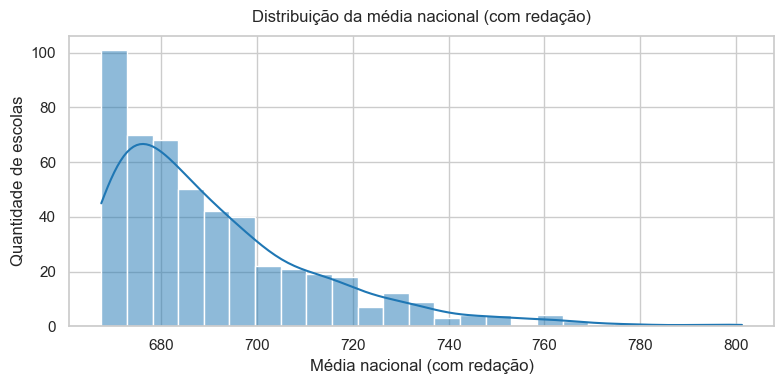

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_col = df['Média nacional (com redação)']

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(target_col, kde=True, color='#1f77b4', bins=25, ax=ax)

ax.set_title('Distribuição da média nacional (com redação)', fontsize=12, pad=10)
ax.set_xlabel('Média nacional (com redação)')
ax.set_ylabel('Quantidade de escolas')

plt.tight_layout()
plt.show()

Ao analisar os dados extraídos da coluna, observa-se que a variável apresenta **assimetria à direita**. A maioria das escolas do top 500 concentra-se no intervalo de 670 a 700 pontos, enquanto uma minoria de instituições estende a cauda da distribuição até valores próximos de 800 pontos.

Em seguida, outra análise importante é verificar a relação entre a `Média nacional (objetivas)` (eixo X) e a `Média nacional (com redação)` (eixo Y).

O gráfico de dispersão (*scatter plot*) abaixo tem como objetivo investigar a presença de uma linha de tendência, o nível de dispersão das escolas e a identificação de possíveis *outliers*.

Para quantificar a força e a direção da associação antes da visualização gráfica, utiliza-se o **Coeficiente de Correlação de Pearson ($r$)**, calculado pela fórmula:

$$r = \frac{\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 \cdot \sum_{i=1}^{n} (Y_i - \bar{Y})^2}}$$

onde:
* $X_i$ e $Y_i$ representam, respectivamente, a média objetiva e a média com redação da escola $i$
* $\bar{X}$ e $\bar{Y}$ são as médias amostrais dessas variáveis
* $n$ é o total de instituições na amostra ($N = 500$).

O valor de $r$ varia entre $-1$ e $+1$. Um valor próximo de $+1$ indica forte correlação linear positiva. 

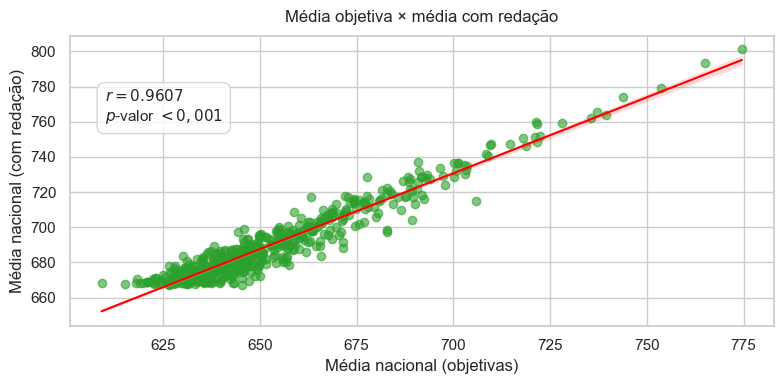

In [5]:
from scipy.stats import pearsonr

x_objetivas = df['Média nacional (objetivas)']
y_target = df['Média nacional (com redação)']

r_valor, p_valor = pearsonr(x_objetivas, y_target)

fig, ax = plt.subplots(figsize=(8, 4))
sns.regplot(
    x=x_objetivas, 
    y=y_target, 
    scatter_kws={'alpha':0.6, 'color':'#2ca02c'}, 
    line_kws={'color':'red', 'linewidth':1.5}, 
    ax=ax
)

texto_r = f'$r = {r_valor:.4f}$\n$p$-valor $< 0,001$'
ax.text(
    0.05, 0.82, texto_r, transform=ax.transAxes, fontsize=11,
    verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#cccccc')
)

ax.set_title('Média objetiva × média com redação', fontsize=12, pad=10)
ax.set_xlabel('Média nacional (objetivas)')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

Analisando o gráfico acima, observa-se uma forte tendência ascendente contínua. Conforme a média das provas objetivas aumenta, a média com redação cresce de forma diretamente proporcional, confirmando o caráter predominantemente linear da relação entre as duas variáveis no topo do desempenho. Além disso, a proximidade estreita dos pontos em relação à linha vermelha reflete uma altíssima correlação positiva ($r \approx 0{,}96$), o que indica que o rendimento nas provas objetivas atua como explicativo da nota final.

A pequena dispersão vertical observada ao longo da reta representa a variabilidade residual decorrente do efeito individual da nota de redação: enquanto escolas situadas acima da reta de regressão conseguem "alavancar" sua média final por meio de um bom rendimento discursivo, pontos abaixo da linha representam instituições nas quais a nota de redação reduziu o rendimento médio acumulado nas objetivas. Por fim, nota-se que tanto no extremo superior (médias objetivas acima de 750) quanto no extremo inferior (médias objetivas abaixo de 625), a dispersão se mantém perfeitamente alinhada com a tendência global, sem a presença de outliers decorrentes de erros de medição.

Após constatar a forte correlação entre as provas objetivas e a média final, é interessante investigar como os fatores contextuais e institucionais se comportam ao longo dessa distribuição de desempenho. Nesse sentido, a dependência administrativa apresenta-se como uma dimensão estrutural relevante no cenário educacional brasileiro. A fim de verificar como o comportamento linear observado anteriormente se desdobra entre as redes de ensino, será utilizado um gráfico de caixa (*boxplot*) para comparar a distribuição da `Média nacional (com redação)` entre as escolas privadas e públicas integrantes do top 500. Essa visualização permite analisar se existem diferenças significativas de mediana, amplitude interquartil e teto de notas entre as duas categorias. 

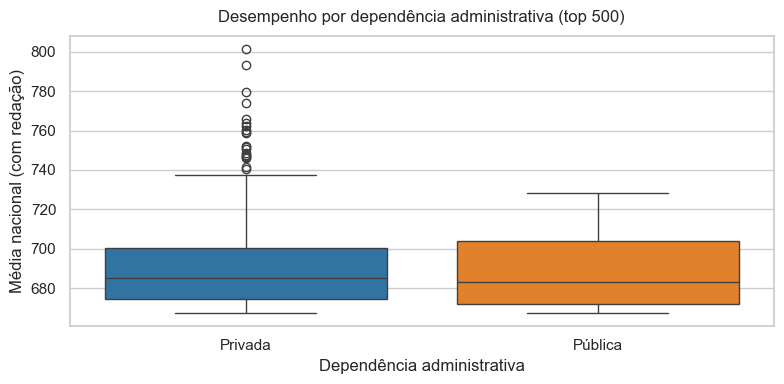

In [6]:
df['Administração'] = df['Administração'].replace({'Público': 'Pública'})

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(
    data=df, 
    x='Administração', 
    y='Média nacional (com redação)', 
    hue='Administração',
    palette=['#1f77b4', '#ff7f0e'], 
    legend=False,
    ax=ax
)

ax.set_title('Desempenho por dependência administrativa (top 500)', fontsize=12, pad=10)
ax.set_xlabel('Dependência administrativa')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

Analisando a distribuição por dependência administrativa, observa-se que as medianas das escolas públicas e privadas integrantes do top 500 situam-se em patamares muito próximos, em torno de 684 pontos, demonstrando que o corpo principal de ambas as redes dentro deste recorte de elite apresenta rendimento similar. 

Contudo, nota-se uma diferença marcante na dispersão e no teto de desempenho: a rede privada exibe maior amplitude interquartil e concentra a totalidade dos *outliers* de altíssima performance, com médias variando entre 740 e 800 pontos. Em contrapartida, as instituições públicas presentes na amostra, compostas predominantemente por colégios federais e institutos de aplicação, demonstram uma distribuição mais compacta e um teto de notas mais contido, sem registros de pontos atípicos na cauda superior.

Compreendido o impacto da dependência administrativa na dispersão das notas, outro fator estrutural relevante é a escala da instituição. A dimensão da do grupo de participantes pode atuar como um elemento moderador do desempenho médio, uma vez que turmas menores tendem a apresentar menor variabilidade interna, enquanto grupos mais numerosos enfrentam o desafio de manter a homogeneidade do rendimento. 

Para analisar essa dinâmica no recorte das 500 melhores instituições, será plotado um gráfico de dispersão (*scatter plot*) relacionando o `Número de participantes` à `Média nacional (com redação)`, com a diferenciação por dependência administrativa. Essa abordagem permite discutir eventuais efeitos de escala, padrões de estabilização da média e a presença de instituições de altíssimo rendimento em diferentes portes escolares.

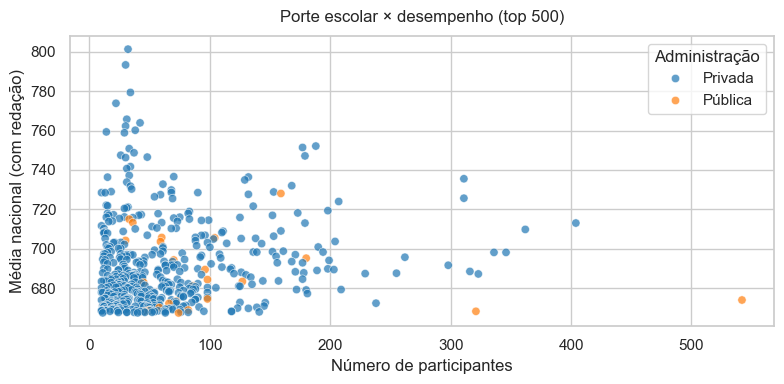

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(
    data=df, 
    x='Número de participantes', 
    y='Média nacional (com redação)', 
    hue='Administração', 
    alpha=0.7, 
    palette=['#1f77b4', '#ff7f0e'], 
    ax=ax
)

ax.set_title('Porte escolar × desempenho (top 500)', fontsize=12, pad=10)
ax.set_xlabel('Número de participantes')
ax.set_ylabel('Média nacional (com redação)')

plt.tight_layout()
plt.show()

A análise de dispersão revela que o desempenho extremo no topo do exame está fortemente associado a instituições de pequeno e médio porte. As pontuações mais elevadas do *dataset*, que ultrapassam o patamar de 740 pontos, concentram-se quase exclusivamente em colégios com turmas reduzidas, variando entre 10 e 50 concluintes inscritos no exame. Conforme a escala do corpo discente se amplia e o número de participantes ultrapassa a marca de 100 alunos, observa-se uma clara convergência das médias para a faixa entre 680 e 720 pontos, evidenciando que em grupos maiores o desempenho tende a se estabilizar devido à maior diversidade no rendimento dos estudantes. Além disso, a sobreposição das categorias administrativas reforça que as poucas instituições públicas do top 500 situam-se majoritariamente no segmento de porte médio a grande, enquanto a rede privada domina tanto os contingentes reduzidos de altíssima performance quanto os grandes colégios de escala.

Após examinar as dimensões de desempenho, dependência administrativa e porte escolar, resta analisar a distribuição territorial dessas instituições no cenário nacional. A localização geográfica é um fator determinante para compreender a concentração de recursos, infraestrutura e redes de ensino de ponta. Para isso, utiliza-se um gráfico para visualizar o volume de escolas presentes no recorte divididas por `Estado`. É indispensável, contudo, pontuar uma ressalva metodológica fundamental: como este *dataset* contempla estritamente um recorte amostral das 500 escolas de maior rendimento do país, e não uma amostragem aleatória ou proporcional de toda a rede de educação básica brasileira, os resultados refletem exclusivamente a representatividade dos estados no topo do exame, não devendo ser extrapolados para inferir a qualidade média do ensino geral de cada Unidade da Federação (UF).

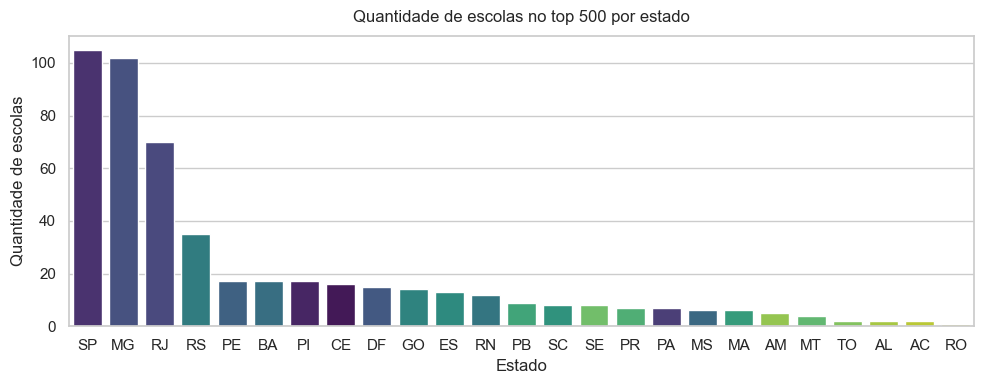

In [8]:
ordem_estados = df['Estado'].value_counts().index

fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(
    data=df, 
    x='Estado', 
    order=ordem_estados, 
    palette='viridis', 
    hue='Estado',
    legend=False,
    ax=ax
)

ax.set_title('Quantidade de escolas no top 500 por estado', fontsize=12, pad=10)
ax.set_xlabel('Estado')
ax.set_ylabel('Quantidade de escolas')

plt.tight_layout()
plt.show()

A análise da distribuição territorial evidencia uma acentuada disparidade regional na presença de instituições no grupo de elite do exame. A Região Sudeste domina expressivamente a amostragem, liderada pelo estado de São Paulo, seguido por Minas Gerais e Rio de Janeiro, que juntos concentram mais da metade de todas as escolas integrantes do top 500. Notam-se também presenças relevantes de estados das regiões Nordeste e Sul, como Ceará e Paraná, sustentados por polos privados de alto desempenho e colégios tradicionais. Esse panorama reflete a centralização de redes educacionais de alta performance e a densidade populacional e socioeconômica dessas regiões, confirmando a relevância de manter a variável de localização como atributo categórico no desenvolvimento do modelo preditivo.

<h2>4 - Tratamento dos dados</h2>

Após uma análise exploratória dos dados, é fundamental realizar o tratamento desses dados, no contexto de Aprendizado de Máquina.

Verifica-se que as variáveis `Estado` e `Administração` são categóricas, diferentemente das outras variáveis, que são numéricas. Por esse motivo, será necessário um tratamento dos dados dessas variáveis, uma vez que a maioria dos algoritmos de Aprendizado de Máquina opera através de operações matemáticas e matrizes numéricas, incapazes de processar diretamente valores em texto (*strings*). 

A variável `Administração`, por ser booleana (pública ou privada), pode ser facilmente convertida para 0s e 1s. Adotando 0 como pública e 1 como privada, tem-se:

In [9]:
mapa_bool = {
    'Pública': 0,
    'Público': 0, 
    'Privada': 1
}

df['Administração'] = df['Administração'].map(
    mapa_bool
)

df.head().style.hide(axis = 'index')

ID Escola,Estado,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes
23246871,CE,1,1,1,1,1,1,774.580000,801.290000,1,32
23246847,CE,2,2,2,2,2,2,765.130000,793.300000,1,30
23246880,CE,3,3,3,3,3,3,753.580000,779.330000,1,34
22144714,PI,1,1,1,1,4,4,743.880000,773.830000,1,22
23235543,CE,4,4,4,4,5,6,737.170000,765.730000,1,31


Diferentemente da dependência administrativa, a variável `Estado` possui natureza categórica nominal sem qualquer relação de ordem implícita entre as regiões. Para evitar que o modelo interprete erroneamente que determinadas siglas possuem peso numérico superior a outras, adota-se o *One-Hot Encoding*, uma técnica que transforma uma variável categórica nominal (como Estado) em várias colunas binárias contendo apenas valores 0 ou 1.

Ou seja, em vez de atribuir números sequenciais para cada estado (o que, por exemplo, poderia fazer o modelo achar que SP tem um "valor" 20 vezes maior que AC), ele cria uma coluna para cada localidade. Assim, se a escola for do Ceará, a coluna Estado_CE recebe 1 e todas as outras colunas de estados recebem 0. O parâmetro drop='first' remove a primeira coluna para evitar redundância matemática (multicolinearidade) no modelo.

In [10]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

estados_encoded = encoder.fit_transform(df[['Estado']])

colunas_estados = encoder.get_feature_names_out(['Estado'])
df_estados = pd.DataFrame(estados_encoded, columns=colunas_estados, index=df.index)

df = pd.concat([df.drop(columns=['Estado']), df_estados], axis=1)

df.head().style.hide(axis = 'index')

ID Escola,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Média nacional (com redação),Administração,Número de participantes,Estado_AL,Estado_AM,Estado_BA,Estado_CE,Estado_DF,Estado_ES,Estado_GO,Estado_MA,Estado_MG,Estado_MS,Estado_MT,Estado_PA,Estado_PB,Estado_PE,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
23246871,1,1,1,1,1,1,774.580000,801.290000,1,32,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246847,2,2,2,2,2,2,765.130000,793.300000,1,30,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23246880,3,3,3,3,3,3,753.580000,779.330000,1,34,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
22144714,1,1,1,1,4,4,743.880000,773.830000,1,22,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
23235543,4,4,4,4,5,6,737.170000,765.730000,1,31,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Tratados os dados, é necessário redefinir os atributos, uma vez que ainda contêm a variável `Estado` e não apresentam as variáveis codificadas pelo processo anterior. 

In [11]:
atributos = [
    col for col in df.columns
    if col != "Média nacional (com redação)"
]

X = df[atributos]
X

,ID Escola,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Administração,Número de participantes,...,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
0,23246871,1,1,1,1,1,1,774.58,1,32,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,23246847,2,2,2,2,2,2,765.13,1,30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,23246880,3,3,3,3,3,3,753.58,1,34,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,22144714,1,1,1,1,4,4,743.88,1,22,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,23235543,4,4,4,4,5,6,737.17,1,31,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,31312177,2,2,100,107,476,576,626.70,1,24,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
496,35144034,1,1,104,169,477,589,626.23,1,40,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
497,31202100,1,1,101,173,477,884,615.26,1,11,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
498,35466153,2,2,105,67,478,272,645.44,1,63,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


<h2>5 - Separação dos dados</h2>

A próxima etapa é separar os dados em dois grupos: treino e teste. Os dados de treino são aqueles que o algoritmo utiliza para aprender os padrões e ajustar seus coeficientes internos, enquanto os dados de teste funcionam como uma prova cega, servindo para avaliar a capacidade de generalização do modelo preditivo em dados inéditos e garantir que ele não esteja apenas decorando a amostra (*overfitting*).

O conjunto de treino representará $90\%$ dos dados, enquanto o de teste $10\%$. Será utilizado train_test_split com semente aleatória (SEED = $42$) para garantir a reprodutibilidade do experimento. 

In [12]:
from sklearn.model_selection import train_test_split

indices_treino, indices_teste = train_test_split(
    df.index, test_size=0.1, random_state=42
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

X_treino = df_treino.reindex(atributos, axis=1)
y_treino = df_treino.reindex(target, axis=1)

X_teste = df_teste.reindex(atributos, axis=1)
y_teste = df_teste.reindex(target, axis=1)

Abaixo, é possível conferir os conjuntos de treino dos atributos (X_treino) e do target (y_treino); e de teste dos atributos (X_teste) e do target (y_teste).

In [13]:
X_treino.head().style.hide(axis = 'index')

ID Escola,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Administração,Número de participantes,Estado_AL,Estado_AM,Estado_BA,Estado_CE,Estado_DF,Estado_ES,Estado_GO,Estado_MA,Estado_MG,Estado_MS,Estado_MT,Estado_PA,Estado_PB,Estado_PE,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
33196214,4,3,13,12,73,78,676.910000,1,93,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
33179999,7,7,29,30,178,193,654.690000,1,45,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31205265,1,2,21,43,131,265,646.010000,1,61,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31346799,2,2,77,77,399,433,633.650000,1,27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
24089214,7,7,7,7,189,250,647.660000,1,70,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [14]:
X_teste.head().style.hide(axis = 'index')

ID Escola,Posição municipal (com redação),Posição municipal (objetivas),Posição estadual (com redação),Posição estadual (objetivas),Posição total (com redação),Posição total (objetivas),Média nacional (objetivas),Administração,Número de participantes,Estado_AL,Estado_AM,Estado_BA,Estado_CE,Estado_DF,Estado_ES,Estado_GO,Estado_MA,Estado_MG,Estado_MS,Estado_MT,Estado_PA,Estado_PB,Estado_PE,Estado_PI,Estado_PR,Estado_RJ,Estado_RN,Estado_RO,Estado_RS,Estado_SC,Estado_SE,Estado_SP,Estado_TO
52034054,8,12,11,15,351,535,628.560000,1,78,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31260908,1,1,10,12,74,80,676.790000,1,19,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
31239666,1,1,70,73,364,423,634.170000,1,30,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
27220885,1,1,1,1,152,167,657.670000,1,155,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
21273456,1,1,1,1,104,151,660.780000,1,13,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [15]:
y_treino.head().style.hide(axis = 'index')

Média nacional (com redação)
714.390000
692.290000
698.770000
671.960000
690.700000


In [16]:
y_teste.head().style.hide(axis = 'index')

Média nacional (com redação)
675.620000
714.070000
674.400000
696.150000
705.240000


<h2>6 - Baseline</h2>

Antes da avaliação dos modelos de Aprendizado de Máquina, será estabelecido um modelo de referência (baseline). Considerado o modelo mais simples da área, ele é empregado para estabelecer um limite mínimo de desempenho que qualquer modelo desenvolvido deve superar. Nesse estudo, será utilizado o **DummyRegressor**, que realiza previsões constantes com base na média dos valores observados no conjunto de treinamento. Como não aprende padrões dos dados, seu papel é servir como referência para avaliar se os demais modelos conseguem extrair informações relevantes dos atributos disponíveis.

Para determinar o desempenho do modelo, calcula-se a Raiz do Erro Quadrático Médio ($\text{RMSE}$), comparando os valores reais ($y_{teste}$) com os previstos. O $\text{RMSE}$ foi escolhido porque é uma ferramenta muito utilizada em problemas de regressão (como nesse caso), traz o valor para a escala real dos dados e por ser sensível a grandes erros, facilitando a identificação do erro na previsão.

In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error
import numpy as np

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_treino, y_treino)
y_pred_baseline = baseline.predict(X_teste)

valor = np.ravel(baseline.constant_)[0]
print(f"Valor previsto pelo baseline: {valor:.2f} pontos")

print(f"RMSE:{root_mean_squared_error(y_teste, y_pred_baseline): .2f} pontos")

Valor previsto pelo baseline: 690.62 pontos
RMSE: 30.64 pontos


Primeiramente, observa-se que o DummyRegressor previu constantemente uma nota de $694.83$ pontos para todas as escolas, valor correspondente à média observada no conjunto de treinamento.

Além disso, obteve-se um $\text{RMSE}$ de $30.64$ pontos. Isso significa que, em média, as previsões realizadas pelo modelo apresentam um desvio de aproximadamente $30.64$ pontos em relação às notas reais das escolas. Esse resultado servirá como referência para comparação com os modelos avaliados nas próximas etapas.

O gráfico abaixo mostra a relação entre os valores reais e previstos pelo modelo baseline. A linha pontilhada vermelha indica a identidade, ou seja, a reta em que o $y_{real}$ é igual ao $y_{previsto}$.

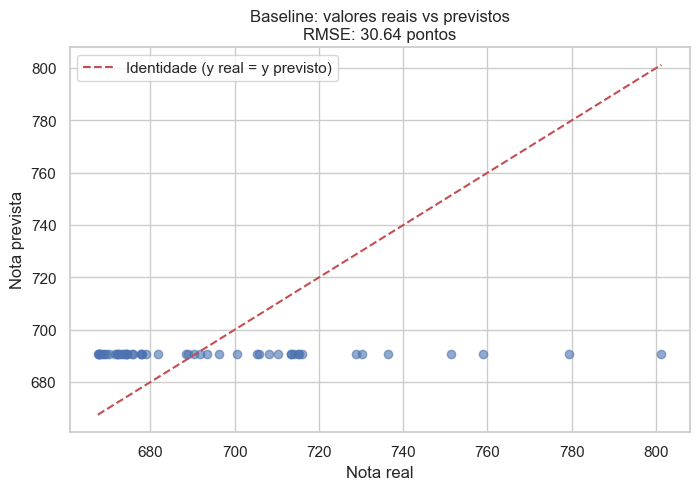

In [18]:
plt.figure(figsize=(8,5))

plt.scatter(y_teste, y_pred_baseline, alpha=0.6)

plt.plot(
    [y_teste.min(), y_teste.max()],
    [y_teste.min(), y_teste.max()],
    'r--',
    label='Identidade (y real = y previsto)'
)

plt.xlabel("Nota real")
plt.ylabel("Nota prevista")
plt.title("Baseline: valores reais vs previstos\nRMSE: 30.64 pontos")
plt.legend()

plt.show()

É possível observar que todas as previsões concentram-se em torno de um único valor, formando uma linha horizontal. A distância dos pontos em relação à linha de identidade indica o erro de previsão do modelo e justifica o $\text{RMSE}$ de $30.64$ pontos obtido anteriormente. Observa-se também que o modelo não acompanha a variabilidade das notas reais das escolas, produzindo a mesma previsão independentemente das características de entrada.

Nas seções a seguir, serão empregados modelos de Aprendizado de Máquina visando reduzir esse erro.

<h2>7 - $k$-Nearest Neighbors ($k$-NN)</h2>

<h3>7.1 - Modelo inicial</h3>

O primeiro modelo de Aprendizado de Máquina empregado será o $k$-Nearest Neighbors ($k$-NN). Este modelo baseia-se na premissa que dados semelhantes ocupam regiões próximas no espaço de entrada. Dessa forma, para realizar uma previsão, o modelo identifica os $k$-vizinhos mais próximos da observação de interesse e utiliza suas informações para estimar o valor da variável alvo. Em problemas de regressão, como o presente estudo, a previsão costuma ser obtida pela média dos valores observados entre os $k$-vizinhos mais próximos.

Como o modelo $k$-NN utiliza medidas de distância para identificar os vizinhos mais próximos, é importante que os atributos estejam em uma mesma escala. Caso contrário, variáveis com valores numericamente maiores podem exercer influência desproporcional no cálculo das distâncias. Por esse motivo, os dados serão normalizados por meio do MinMaxScaler, que transforma cada atributo para o intervalo $[0,1]$ com base em seus valores mínimo e máximo observados. Dessa forma, garante-se que todas as variáveis contribuam de maneira equilibrada para o processo de identificação dos vizinhos mais próximos.

Entretanto, nem todos os atributos necessitam de normalização. As variáveis geradas pelo processo de One-Hot Encoding da coluna `Estado` e a variável `Administração` já assumem valores binários ($0$ ou $1$), encontrando-se naturalmente em uma mesma escala. Por esse motivo, foi utilizado um ColumnTransformer, que permite aplicar o MinMaxScaler apenas às variáveis contínuas, preservando os atributos binários sem alterações.

Para integrar as etapas de pré-processamento e treinamento do modelo, foi utilizada uma pipeline. Uma pipeline executa sequencialmente todas as transformações necessárias antes do treinamento do algoritmo, tornando o código mais organizado e reduzindo a possibilidade de erros.

Além disso, a pipeline contribui para evitar vazamento de dados (*data leakage*), uma vez que os parâmetros da normalização são ajustados exclusivamente a partir do conjunto de treinamento e posteriormente aplicados aos dados de teste.

Vamos iniciar usando $k$ = $3$ vizinhos e distância Euclidiana:

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

colunas_continuas = [
    col for col in X.columns
    if not col.startswith("Estado_") and col != "Administração"
]

preprocessador = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), colunas_continuas)
    ],
    remainder="passthrough"
)

pipeline_knn = Pipeline([
    ("prep", preprocessador),
    ("knn", KNeighborsRegressor(n_neighbors=3))
])

X_verdadeiro = X_teste
y_verdadeiro = y_teste

pipeline_knn.fit(X_treino, y_treino)
y_pred_knn = pipeline_knn.predict(X_verdadeiro)

RMSE_knn = root_mean_squared_error(y_verdadeiro, y_pred_knn)

print(f"O RMSE do modelo foi de{RMSE_knn: .2f} pontos")

O RMSE do modelo foi de 9.46 pontos


O modelo apresentou um $\text{RMSE}$ de $9.46$ pontos, valor significativamente inferior ao observado para o baseline ($30.64$ pontos). Esse resultado indica que a utilização das características das escolas permite obter previsões bem mais precisas do que simplesmente assumir a média das notas observadas.

Analisemos agora o gráfico de relação entre $y_{real}$ e $y_{previsto}$:

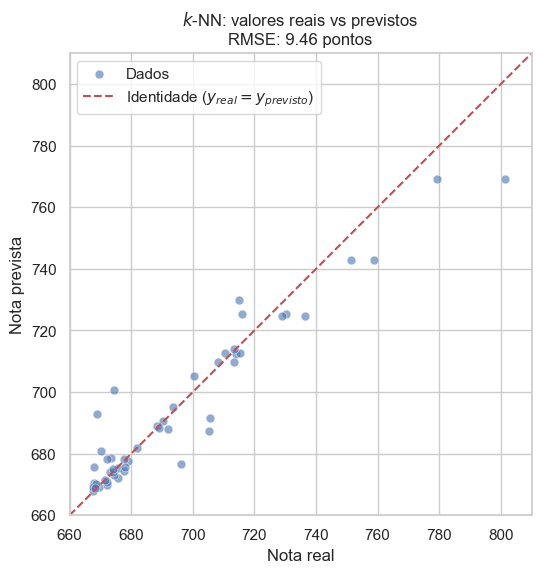

In [20]:
import seaborn as sns
import numpy as np

y_teste_1d = np.array(y_teste).flatten()
y_pred_knn_1d = np.array(y_pred_knn).flatten()

sns.set_theme(style="whitegrid", rc={"figure.figsize": (6, 6)})
intervalo = [660, 810]

eixo = sns.scatterplot(x=y_teste_1d, y=y_pred_knn_1d, label="Dados", alpha=0.6, s=40)
eixo.plot(intervalo, intervalo, "r--", label="Identidade ($y_{real} = y_{previsto}$)", linewidth=1.5)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=f"$k$-NN: valores reais vs previstos\nRMSE: {RMSE_knn:.2f} pontos",
    xlim=intervalo,
    ylim=intervalo,
    aspect="equal",
)

eixo.legend();

Observa-se que a maioria dos pontos está concentrada próxima à linha de identidade ($y_{real}=y_{previsto}$), indicando que as previsões realizadas pelo modelo se aproximam dos valores reais observados. Esse comportamento contrasta com o modelo baseline, no qual as previsões permaneciam praticamente constantes.

Nota-se também que os maiores desvios ocorrem para algumas escolas com notas mais elevadas, sugerindo uma leve tendência do modelo em subestimar valores extremos. Ainda assim, a proximidade geral dos pontos em relação à diagonal evidencia que o $k$-NN foi capaz de capturar os padrões presentes nos dados, produzindo previsões consideravelmente mais precisas.

Vamos agora se debruçar sobre os hiperparâmetros do modelo, a fim de tentar reduzir o $\text{RMSE}$.

<h3>7.2 - Otimização de hiperparâmetros no $k$-NN</h3>

O desempenho do algoritmo $k$-NN depende diretamente da escolha de seus hiperparâmetros. Entre os mais importantes, estão o número de vizinhos considerados ($k$), o peso e a métrica de distância utilizada ($p$) para comparar as observações. Dessa forma, serão avaliadas diferentes combinações desses hiperparâmetros com o objetivo de identificar a configuração que produz o menor erro $\text{RMSE}$.

Antes, contudo, é fundamental contextualizar ao que correspondem os pesos. Em $k$-NN, os pesos definem o nível de importância ou a força do voto que cada vizinho mais próximo tem ao definir o palpite final do modelo. Os dois principais pesos são uniform e distance. Na opção uniform, o algoritmo trata todos os vizinhos de forma totalmente igualitária, de modo que o poder de decisão de um vizinho colado ao ponto de teste é exatamente o mesmo de um vizinho localizado no limite mais distante do raio de busca. Por outro lado, na opção distance, o $k$-NN assume um comportamento muito mais refinado ao ponderar os votos pelo inverso da distância matemática entre os pontos, garantindo que os vizinhos que são genuinamente mais similares e próximos tenham uma influência muito maior na previsão do que os dados mais afastados, protegendo o modelo contra ruídos e distorções periféricas.

Neste trabalho, a métrica de distância será controlada pelo parâmetro $p$ da distância de Minkowski. Dependendo do valor adotado para $p$, obtêm-se diferentes formas de medir a distância entre observações. Quando $p = 1$, a métrica corresponde à distância de Manhattan, calculada somando os valores absolutos das diferenças em cada coordenada [3]. Ela representa o deslocamento estritamente ao longo dos eixos cartesianos, como o trajeto de um carro seguindo a grade de quadras de uma cidade. Quando $p=2$, obtém-se a distância Euclidiana, que representa a menor linha reta direta entre dois pontos no espaço, por meio da raiz quadrada da soma das diferenças ao quadrado de cada dimensão. Por último, quando $p=3$, tem-se a distância $L_3$, determinada pela raiz cúbica da soma das diferenças elevadas ao cubo, penalizando grandes discrepâncias em dimensões individuais de forma mais rigorosa do que a métrica euclidiana. Assim, pode-se avaliar qual forma de medir distâncias se adapta melhor ao comportamento dos nossos dados.

Para realizar essa busca de forma sistemática, será utilizado o módulo `Optuna`, que permite avaliar automaticamente diferentes combinações de hiperparâmetros e selecionar aquelas associadas ao menor $\text{RMSE}$ médio observado durante a validação cruzada.

Vamos primeiramente importar o módulo e reduzir a verbosidade das mensagens exibidas durante a execução da busca, tornando a saída mais limpa e fácil de interpretar.

In [21]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

Em seguida, é o momento de definir uma função capaz de construir instâncias do modelo a partir dos hiperparâmetros sugeridos pelo `Optuna`. Nessa função, o `Optuna` poderá variar o número de vizinhos entre $1$ e $350$, o método de ponderação dos vizinhos e o parâmetro $p$ da distância de Minkowski.

In [22]:
def cria_instancia_modelo_knn(trial):

    parametros = {
        "n_neighbors": trial.suggest_int(
            "n_neighbors",
            1,
            350
        ),
        "weights": trial.suggest_categorical(
            "weights",
            ["uniform", "distance"]
        ),
        "p": trial.suggest_int(
            "p",
            1,
            3
        )
    }

    modelo = Pipeline([
        ("prep", preprocessador),
        ("knn", KNeighborsRegressor(**parametros))
    ])

    return modelo

Para comparar diferentes combinações de hiperparâmetros, é necessário definir uma função objetivo. Essa função será responsável por treinar o modelo e retornar o $\text{RMSE}$ médio obtido por validação cruzada.

In [23]:
from sklearn.model_selection import cross_val_score

def funcao_objetivo_knn(trial):

    modelo = cria_instancia_modelo_knn(trial)

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

Após definir a função objetivo, cria-se um estudo do Optuna. Como o objetivo é minimizar o $\text{RMSE}$, o estudo será configurado na direção de minimização.

In [24]:
estudo_knn = optuna.create_study(
    direction="minimize"
)

Vamos então avaliar $100$ combinações distintas de hiperparâmetros. Ao final da busca, será possível inspecionar a configuração que produziu o menor $\text{RMSE}$ médio.

In [25]:
estudo_knn.optimize(
    funcao_objetivo_knn,
    n_trials=100
)

print("Melhor hiperparâmetro:")
print(estudo_knn.best_params)
print(f"\nMelhor RMSE médio: {estudo_knn.best_value:.2f} pontos")

Melhor hiperparâmetro:
{'n_neighbors': 2, 'weights': 'distance', 'p': 1}

Melhor RMSE médio: 6.52 pontos


É perceptível que o melhor hiperparâmetro encontrado pelo `Optuna` foi considerando $k=2$, peso 'distance' e $p=1$ (distância Manhattan), obtendo $\text{RMSE}$ médio = $6.52$ pontos.

Em teoria, valores reduzidos de $k$ tendem a aumentar a variância do modelo, tornando-o mais sensível às observações vizinhas. Entretanto, como foi considerado um amplo espaço de busca e realizada a validação cruzada durante a otimização, esse resultado sugere que o valor de $k=2$ é adequado ao desempenho do modelo. 

Graficamente, é possível observar o desempenho do modelo com a variação do $k$:

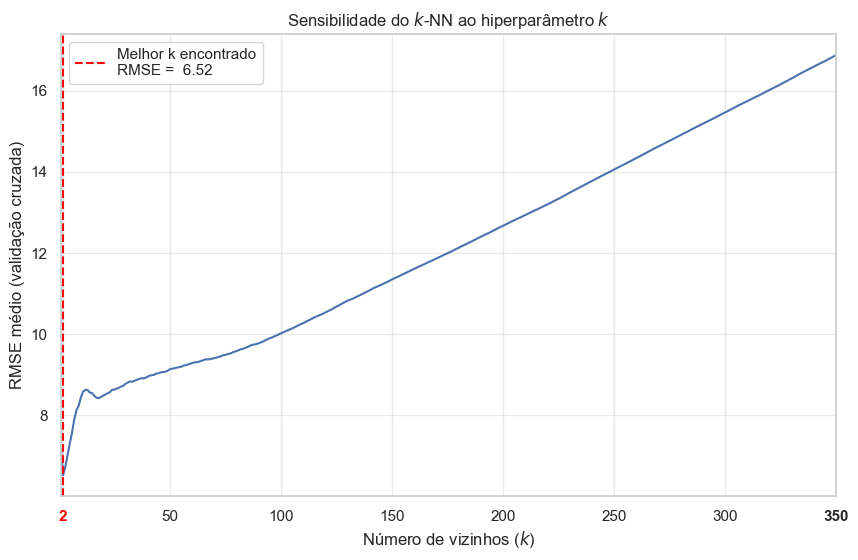

In [26]:
k_vizinhos = range(1, 351)

rmses = []

for k in k_vizinhos:

    pipeline = Pipeline([
        ("prep", preprocessador),
        ("knn", KNeighborsRegressor(
            n_neighbors=k,
            weights="distance",
            p=1
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    rmses.append(-scores.mean())

melhor_k = k_vizinhos[np.argmin(rmses)]
melhor_rmse = min(rmses) 

plt.figure(figsize=(10,6))

plt.plot(k_vizinhos, rmses)

plt.axvline(
    x=melhor_k,
    color="red",
    linestyle="--",
    label=f"Melhor k encontrado\nRMSE = {melhor_rmse: .2f}"
)

plt.xlim(1, 350) 

valores_padrao_x = list(plt.xticks()[0])

valores_padrao_x = [v for v in valores_padrao_x if 0 < v < 350]

valores_padrao_x.append(melhor_k)
valores_padrao_x.append(350)

valores_padrao_x = sorted(list(set(valores_padrao_x)))

plt.xticks(valores_padrao_x)

ax = plt.gca()
for tick in ax.get_xticklabels():
    try:
        texto_num = int(float(tick.get_text()))
        if texto_num == melhor_k:
            tick.set_color("red")
            tick.set_weight("bold")
        elif texto_num == 350:
            tick.set_weight("bold") 
    except ValueError:
        pass

plt.xlabel("Número de vizinhos ($k$)")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Sensibilidade do $k$-NN ao hiperparâmetro $k$")

plt.legend()
plt.grid(alpha=0.4)

plt.show()

Observa-se que o modelo atingiu seu menor erro em $k=2$ e, a partir desse ponto, o $\text{RMSE}$ médio teve uma tendência de crescimento. Para uma melhor análise, vamos aproximar nosso olhar à região do melhor $k$ encontrado pelo `Optuna`:

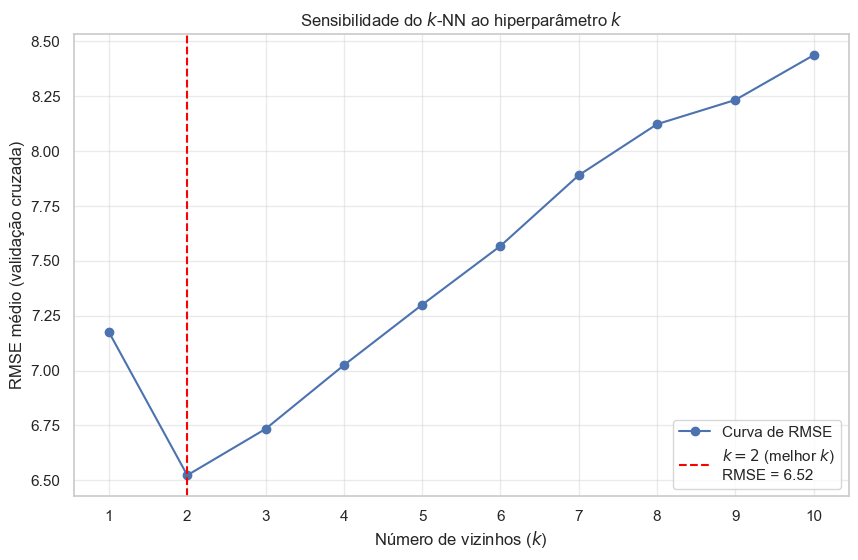

In [27]:
k_vizinhos = range(1, 11)

rmses = []

for k in k_vizinhos:

    pipeline = Pipeline([
        ("prep", preprocessador),
        ("knn", KNeighborsRegressor(
            n_neighbors=k,
            weights="distance",
            p=1
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    rmses.append(-scores.mean())

melhor_k = k_vizinhos[np.argmin(rmses)]
melhor_rmse = min(rmses) 
rmse_k3 = rmses[2] 

plt.figure(figsize=(10,6))
plt.plot(k_vizinhos, rmses, marker='o', label="Curva de RMSE") 

plt.axvline(
    x=melhor_k,
    color="red",
    linestyle="--",
    label=f"$k=2$ (melhor $k$)\nRMSE = {melhor_rmse:.2f}"
)

# plt.axhline(
#     y=rmse_k3,
#     color="blue",
#     linestyle=":",
#     alpha=0.7,
#     label=f"Valor em $k=3$\nRMSE = {rmse_k3:.2f}"
# )

plt.xlabel("Número de vizinhos ($k$)")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Sensibilidade do $k$-NN ao hiperparâmetro $k$")

plt.xticks(range(1, 11)) 

plt.legend()
plt.grid(alpha=0.4)

plt.show()

A análise local nos permite identificar que o $k$ que fornece o menor $\text{RMSE}$ médio é realmente $k=2$. Isso encerra nossa análise de melhor $k$.

Vamos então graficamente visualizar o impacto da variação do número de vizinhos e da métrica de distância no valor do $\text{RMSE}$ médio e, consequentemente, no desempenho do modelo:

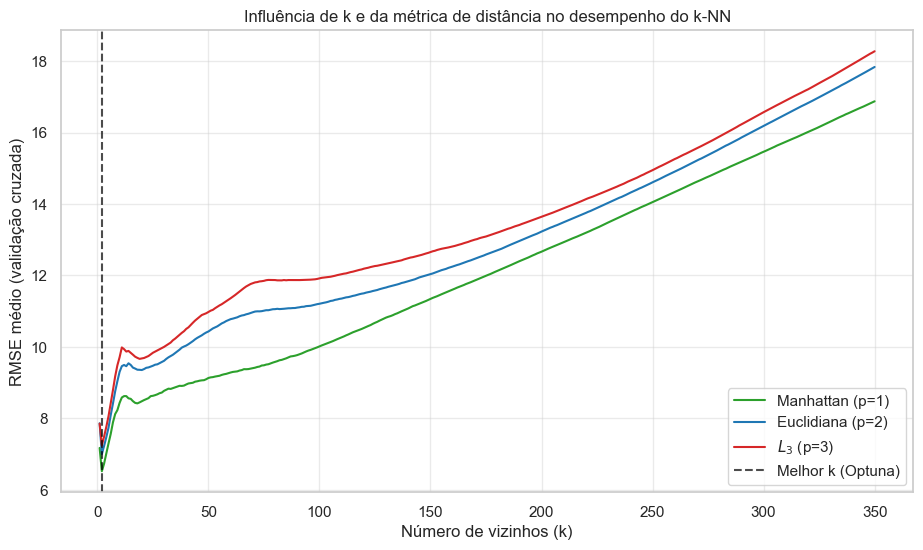

In [28]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

k_vizinhos = range(1, 351)

metricas = [
    {"p": 1, "nome": "Manhattan (p=1)", "cor": "#2ca02c"},
    {"p": 2, "nome": "Euclidiana (p=2)", "cor": "#1f77b4"},
    {"p": 3, "nome": r"$L_3$ (p=3)", "cor": "#d62728"}
]

resultados = []

for metrica in metricas:

    rmses = []

    for k in k_vizinhos:

        pipeline = Pipeline([
            ("prep", preprocessador),
            ("knn", KNeighborsRegressor(
                n_neighbors=k,
                p=metrica["p"],
                weights="distance"
            ))
        ])

        scores = cross_val_score(
            pipeline,
            X_treino,
            y_treino,
            cv=5,
            scoring="neg_root_mean_squared_error"
        )

        rmses.append(-scores.mean())

    resultados.append({
        "nome": metrica["nome"],
        "cor": metrica["cor"],
        "rmses": rmses
    })

plt.figure(figsize=(11,6))

for resultado in resultados:

    plt.plot(
        k_vizinhos,
        resultado["rmses"],
        label=resultado["nome"],
        color=resultado["cor"]
    )

plt.axvline(
    x=2,
    color="black",
    linestyle="--",
    alpha=0.7,
    label="Melhor k (Optuna)"
)

plt.xlabel("Número de vizinhos (k)")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Influência de k e da métrica de distância no desempenho do k-NN")

plt.grid(alpha=0.4)
plt.legend()

plt.show()

O gráfico acima evidencia que a métrica Manhattan ($p=1$) apresentou os menores valores de $\text{RMSE}$ médio para praticamente todos os valores de $k$ avaliados. Esse comportamento sugere que a similaridade entre as escolas é melhor representada pela soma das diferenças absolutas entre os atributos do que por métricas que elevam essas diferenças a potências maiores.

Em contrapartida, as métricas Euclidiana ($p=2$) e $L_3$ ($p=3$) apresentaram erros mais elevados. Como essas métricas atribuem maior peso a discrepâncias de grande magnitude, observações que diferem significativamente em alguns atributos exercem influência mais intensa no cálculo das distâncias. Nesse conjunto de dados, esse comportamento parece prejudicar a identificação dos vizinhos mais representativos, resultando em um desempenho inferior ao obtido pela distância Manhattan.

Além disso, observa-se que as três curvas apresentam tendência crescente à medida que o número de vizinhos aumenta. Esse resultado indica que previsões locais são mais adequadas para o problema estudado. À medida que mais vizinhos são incorporados à previsão, observações progressivamente menos semelhantes passam a influenciar o resultado, aumentando o erro de generalização do modelo.

Para finalizar nosso estudo de $k$-NN, vamos analisar graficamente a relação entre $y_{real}$ e $y_{previsto}$ no melhor hiperparâmetro encontrado pelo `Optuna`:

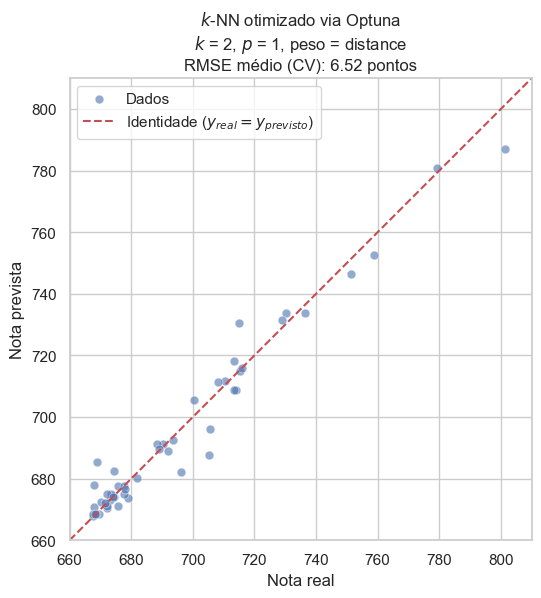

In [29]:
melhores_parametros = estudo_knn.best_params

pipeline_knn_otimizado = Pipeline([
    ("prep", preprocessador),
    ("knn", KNeighborsRegressor(
        n_neighbors=melhores_parametros["n_neighbors"],
        weights=melhores_parametros["weights"],
        p=melhores_parametros["p"]
    ))
])

pipeline_knn_otimizado.fit(X_treino, y_treino)

y_pred_knn_otimizado = pipeline_knn_otimizado.predict(X_teste)

RMSE_knn_otimizado = estudo_knn.best_value

y_teste_1d = np.array(y_teste).flatten()
y_pred_1d = np.array(y_pred_knn_otimizado).flatten()

sns.set_theme(
    style="whitegrid",
    rc={"figure.figsize": (6, 6)}
)

intervalo = [660, 810]

eixo = sns.scatterplot(
    x=y_teste_1d,
    y=y_pred_1d,
    alpha=0.6,
    s=40,
    label="Dados"
)

eixo.plot(
    intervalo,
    intervalo,
    "r--",
    linewidth=1.5,
    label="Identidade ($y_{real}=y_{previsto}$)"
)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=(
        "$k$-NN otimizado via Optuna\n"
        f"$k$ = {melhores_parametros['n_neighbors']}, "
        f"$p$ = {melhores_parametros['p']}, "
        f"peso = {melhores_parametros['weights']}\n"
        f"RMSE médio (CV): {RMSE_knn_otimizado:.2f} pontos"
    ),
    xlim=intervalo,
    ylim=intervalo,
)

eixo.set_aspect("equal")

eixo.legend();

Observa-se que a maior parte das previsões se concentra próxima à linha de identidade ($y_{real}=y_{previsto}$), indicando elevada concordância entre os valores previstos e observados.

Em comparação com a configuração inicial do modelo, nota-se uma menor dispersão dos pontos em torno da diagonal, refletindo a redução do $\text{RMSE}$ obtida durante o processo de otimização. Os maiores desvios permanecem associados a algumas escolas com notas mais elevadas, porém em quantidade reduzida. De modo geral, o gráfico confirma visualmente a melhora de desempenho observada após a escolha dos hiperparâmetros realizada pelo Optuna.

<h3>7.3 - Conclusão</h3>

A otimização dos hiperparâmetros permitiu reduzir o $\text{RMSE}$ do modelo de $9.46$ para $6.52$ pontos, evidenciando a importância da escolha adequada dos parâmetros do algoritmo. A melhor configuração encontrada pelo `Optuna` utilizou $k=2$, ponderação por distância (pesos = distance) e distância Manhattan ($p=1$). 

A análise de sensibilidade mostrou que a distância Manhattan apresentou desempenho consistentemente superior às métricas Euclidiana e $L_3$ para todos os valores de $k$ avaliados. Além disso, verificou-se que os menores erros foram obtidos para valores reduzidos de $k$, indicando que relações muito locais entre as observações são particularmente importantes para prever o desempenho das escolas.

Contudo, a fim de buscar reduções ainda mais expressivas no erro de predição, a próxima seção será dedicada à aplicação e ao ajuste do modelo de Regressão Linear, avaliando se uma abordagem paramétrica baseada em relações lineares pode superar o desempenho alcançado pelo $k$-NN.

<h2>8 - Regressão Linear</h2>

<h3>8.1 - Modelo inicial</h3>

O segundo modelo avaliado neste trabalho será a Regressão Linear. Diferentemente do $k$-NN, que realiza previsões com base na proximidade entre observações, a Regressão Linear busca modelar explicitamente a relação entre os atributos de entrada e o *target* por meio de uma combinação linear dos atributos.

Em sua forma geral, a regressão linear múltipla pode ser representada pela equação:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n + \varepsilon$$

Nessa expressão, $y$ corresponde ao valor previsto pelo modelo, $\beta_0$ representa o intercepto da reta de regressão, $\beta_1,\beta_2,\ldots,\beta_n$ são os coeficientes associados a cada atributo e $\varepsilon$ representa o erro da predição. Durante o treinamento, o algoritmo estima os coeficientes que minimizam a diferença entre os valores previstos e os valores observados.

Como a Regressão Linear assume relações aproximadamente lineares entre os atributos e o *target*, seu desempenho servirá como referência para avaliar o quanto relações lineares são capazes de explicar as diferenças de desempenho entre as escolas. Além disso, por ser um modelo simples e altamente interpretável, os coeficientes estimados podem fornecer informações sobre a influência de cada atributo na previsão das notas.

Assim como realizado para o modelo $k$-NN, inicialmente será avaliada uma configuração inicial da Regressão Linear. Como esse algoritmo também pode ser influenciado pela escala dos atributos, será utilizada uma pipeline contendo as mesmas etapas de pré-processamento adotadas anteriormente.

In [30]:
from sklearn.linear_model import LinearRegression

pipeline_rl = Pipeline([
    ("prep", preprocessador),
    ("regressao", LinearRegression())
])

pipeline_rl.fit(X_treino, y_treino)

y_pred_rl = pipeline_rl.predict(X_teste)

RMSE_rl = root_mean_squared_error(
    y_teste,
    y_pred_rl
)

print(f"RMSE: {RMSE_rl:.2f} pontos")

RMSE: 3.60 pontos


O $\text{RMSE}$ obtido nesse modelo inicial foi de $3.60$ pontos, um erro consideravelmente menor que o obtido no $k$-NN otimizado. Vejamos o gráfico de relação entre $y_{real}$ e $y_{previsto}$:

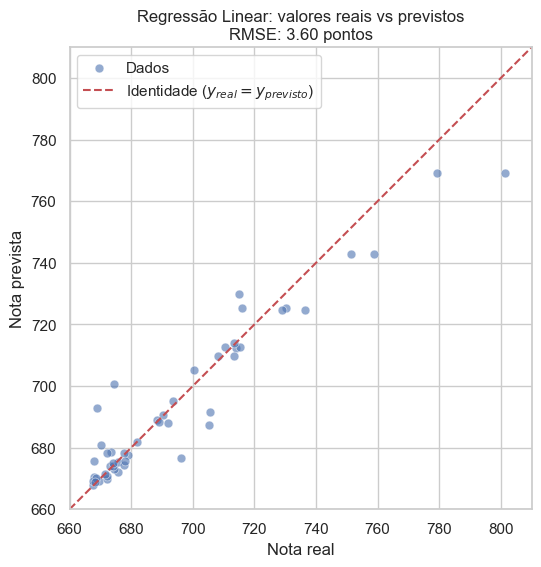

In [31]:
y_teste_1d = np.array(y_teste).flatten()
y_pred_rl_1d = np.array(y_pred_rl).flatten()

sns.set_theme(style="whitegrid", rc={"figure.figsize": (6, 6)})
intervalo = [660, 810]

eixo = sns.scatterplot(x=y_teste_1d, y=y_pred_knn_1d, label="Dados", alpha=0.6, s=40)
eixo.plot(intervalo, intervalo, "r--", label="Identidade ($y_{real} = y_{previsto}$)", linewidth=1.5)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=f"Regressão Linear: valores reais vs previstos\nRMSE: {RMSE_rl:.2f} pontos",
    xlim=intervalo,
    ylim=intervalo,
    aspect="equal",
)

eixo.legend();

Observa-se que a maior parte dos pontos encontra-se muito próxima da linha de identidade ($y_{real}=y_{previsto}$), indicando elevada concordância entre as previsões realizadas pelo modelo e os valores observados.

Nota-se que a dispersão dos pontos em torno da diagonal é relativamente pequena ao longo de quase toda a faixa de notas analisada, o que é consistente com o RMSE de $3.60$ pontos obtido pelo modelo. Esse resultado sugere que as características das escolas apresentam uma relação aproximadamente linear com o *target*, permitindo que a Regressão Linear capture grande parte da variabilidade presente nos dados.

Os maiores desvios ocorrem em algumas escolas com notas mais elevadas, próximas de $780$ e $800$ pontos, para as quais o modelo tende a produzir previsões ligeiramente inferiores às observadas. Ainda assim, o comportamento geral indica excelente capacidade preditiva, com erros de pequena magnitude quando comparados à escala das notas analisadas.

Vamos agora realizar uma otimização de hiperparâmetros usando `Optuna`.

<h3>8.2 - Otimização de hiperparâmetros na Regressão Linear</h3>

Embora a Regressão Linear tradicional tenha apresentado excelente desempenho, o modelo possui poucos hiperparâmetros passíveis de otimização. Para isso, serão avaliadas as abordagens Lasso ($L_1$) e Ridge ($L_2$), cujos hiperparâmetros de regularização serão otimizados utilizando o `Optuna`.

<h4>8.2.1 - Regressão Lasso ($L_1$)</h4>

A Regressão Lasso estende a Regressão Linear tradicional por meio da adição de um termo de penalização aos coeficientes do modelo. Essa penalização utiliza a norma $L_1$, que tende a reduzir a magnitude dos coeficientes e pode até mesmo levar alguns deles a zero, atuando como um mecanismo de seleção automática de atributos.

$$\min \left( \sum (y_i-\hat y_i)^2 + \alpha \sum |\beta_j| \right)$$

O principal hiperparâmetro da Regressão Lasso é $\alpha$, responsável por controlar a intensidade da regularização. Valores muito pequenos fazem com que o modelo se comporte de maneira semelhante à Regressão Linear tradicional, enquanto valores maiores aumentam a penalização aplicada aos coeficientes. Dessa forma, será utilizado o módulo `Optuna` para identificar o valor de $\alpha$ que minimiza o $\text{RMSE}$ do modelo.

Da mesma forma que foi realizado na otimização dos hiperparâmetros do modelo $k$-NN, será instanciado um modelo, definida uma função objetivo e criado um estudo. Em seguida, o estudo será otimizado por meio da avaliação de diferentes configurações do hiperparâmetro $\alpha$, buscando minimizar o $\text{RMSE}$ médio obtido por validação cruzada. Por fim, a melhor configuração encontrada entre as $150$ combinações realizadas será utilizada para treinar e avaliar a versão otimizada do modelo.

In [32]:
from sklearn.linear_model import Lasso

def cria_instancia_modelo_rl1(trial):

    alpha = trial.suggest_float(
        "alpha",
        1e-5,
        100,
        log=True
    )

    modelo = Pipeline([
        ("prep", preprocessador),
        ("lasso", Lasso(alpha=alpha, max_iter=10000000))
    ])

    return modelo

In [33]:
def funcao_objetivo_rl1(trial):

    modelo = cria_instancia_modelo_rl1(trial)

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [34]:
estudo_rl1 = optuna.create_study(
    direction="minimize"
)

In [35]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

estudo_rl1.optimize(
    funcao_objetivo_rl1,
    n_trials=150
)

print("Melhor hiperparâmetro:")
print(estudo_rl1.best_params)

print(f"\nMelhor RMSE médio: {estudo_rl1.best_value:.2f} pontos")

Melhor hiperparâmetro:
{'alpha': 0.010945704792141839}

Melhor RMSE médio: 2.79 pontos


Verifica-se que o melhor hiperparâmetro encontrado foi $\alpha \approx 0.0108$, indicando $\text{RMSE}$ médio de $2.79$ pontos. 

Vamos graficamente explorar a influência de $\alpha$ no desempenho da Regressão Lasso:

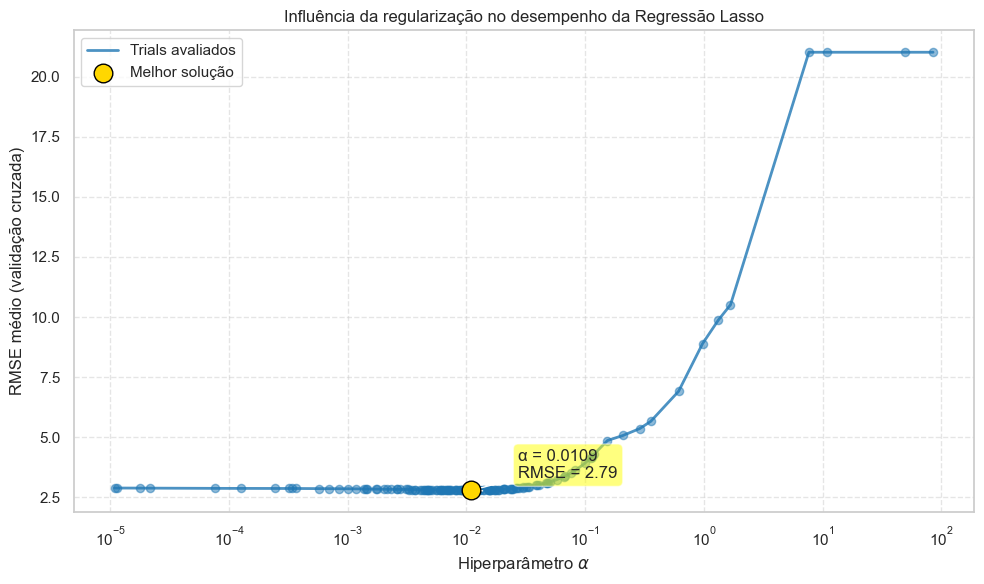

In [36]:
resultados = estudo_rl1.trials_dataframe()

resultados = resultados[resultados["state"] == "COMPLETE"]

resultados = resultados.sort_values("params_alpha")

melhor_alpha = estudo_rl1.best_params["alpha"]
melhor_rmse = estudo_rl1.best_value

plt.figure(figsize=(10, 6))

plt.plot(
    resultados["params_alpha"],
    resultados["value"],
    color="#1f77b4",
    linewidth=2,
    alpha=0.8,
    label="Trials avaliados"
)

plt.scatter(
    resultados["params_alpha"],
    resultados["value"],
    color="#1f77b4",
    alpha=0.5,
    s=35
)

plt.scatter(
    melhor_alpha,
    melhor_rmse,
    color="gold",
    edgecolor="black",
    s=180,
    zorder=5,
    label="Melhor solução"
)

plt.annotate(
    (
        f"α = {melhor_alpha:.4f}\n"
        f"RMSE = {melhor_rmse:.2f}"
    ),
    xy=(melhor_alpha, melhor_rmse),
    xytext=(melhor_alpha * 2.5, melhor_rmse + 0.5),
    arrowprops=dict(arrowstyle="->"),
    bbox=dict(
        boxstyle="round,pad=0.3",
        fc="yellow",
        alpha=0.5
    )
)

plt.xscale("log")

plt.xlabel(r"Hiperparâmetro $\alpha$")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Influência da regularização no desempenho da Regressão Lasso")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

O gráfico mostra que o $\text{RMSE}$ diminuiu gradualmente para valores reduzidos de $\alpha$, mantendo-se relativamente estável e próximo ao mínimo encontrado no ponto de melhor $\alpha$. A partir desse ponto ideal, o erro apresenta uma tendência de crescimento; inicialmente, cresce de forma rápida e ultrapassa os $20$ pontos para valores elevados de penalização, e posteriormente atinge um patamar de estabilidade em torno de $\alpha \approx 8$. Esse comportamento indica que, enquanto uma regularização leve preserva a capacidade preditiva, uma penalização excessiva reduz demasiadamente os coeficientes do modelo, levando à perda de informações relevantes para a previsão das notas das escolas.

Mas esse gráfico não nos dá uma visão tão detalhada do melhor hiperparâmetro do modelo. Por isso, vamos observar mais localmente:

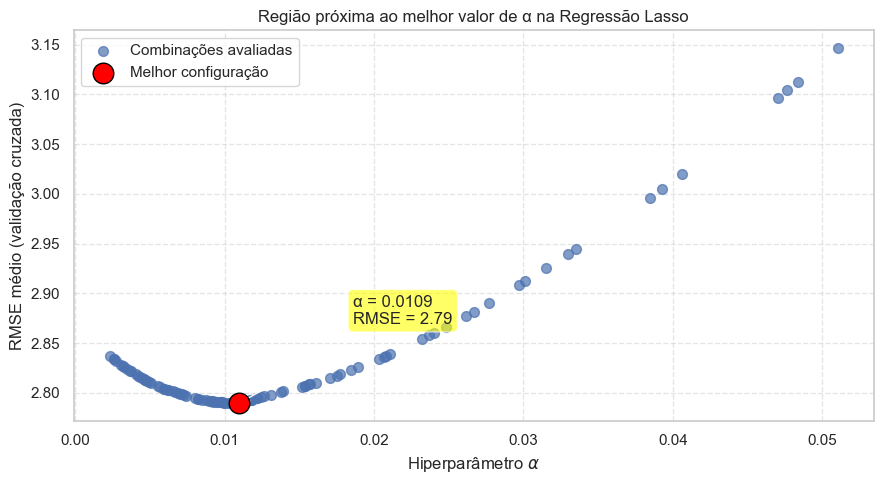

In [37]:
resultados = estudo_rl1.trials_dataframe()

melhor_alpha = estudo_rl1.best_params["alpha"]
melhor_rmse = estudo_rl1.best_value

resultados_zoom = resultados[
    (resultados["params_alpha"] >= melhor_alpha / 5) &
    (resultados["params_alpha"] <= melhor_alpha * 5)
].copy()

plt.figure(figsize=(9, 5))

plt.scatter(
    resultados_zoom["params_alpha"],
    resultados_zoom["value"],
    color="#4c72b0",
    alpha=0.7,
    s=50,
    label="Combinações avaliadas"
)

plt.scatter(
    melhor_alpha,
    melhor_rmse,
    color="red",
    edgecolor="black",
    s=220,
    zorder=5,
    label="Melhor configuração"
)

plt.annotate(
    f"α = {melhor_alpha:.4f}\nRMSE = {melhor_rmse:.2f}",
    xy=(melhor_alpha, melhor_rmse),
    xytext=(melhor_alpha * 1.7, melhor_rmse + 0.08),
    arrowprops=dict(arrowstyle="->"),
    bbox=dict(
        boxstyle="round,pad=0.3",
        fc="yellow",
        alpha=0.6
    )
)

plt.xlabel(r"Hiperparâmetro $\alpha$")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Região próxima ao melhor valor de α na Regressão Lasso")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

Nesse gráfico, observa-se de forma mais clara que o valor de $\alpha$ que resultou no menor $\text{RMSE}$ médio corresponde justamente ao hiperparâmetro selecionado pelo `Optuna`($\alpha \approx 0.0108$). Além disso, nota-se que pequenas variações em torno desse valor resultam em erros mais elevados, reforçando a adequação da solução encontrada durante o processo de otimização.

Comparativamente, a Regressão Linear tradicional apresentou RMSE de $3.60$ pontos. Assim, a introdução da regularização $L_1$ proporcionou uma redução de aproximadamente $22.5\%$ no erro de previsão, evidenciando que uma penalização moderada dos coeficientes contribuiu para melhorar a capacidade de generalização do modelo.

Após analisar os efeitos da regularização $L_1$, será avaliada a Regressão Ridge, que emprega a regularização $L_2$ como alternativa para controlar a complexidade do modelo.

<h4>8.2.2 - Regressão Ridge ($L_1$)</h4>

Enquanto a Regressão Lasso utiliza a regularização $L_1$, a Regressão Ridge emprega a regularização $L_2$, adicionando aos quadrados mínimos um termo proporcional ao quadrado dos coeficientes do modelo. O objetivo dessa penalização é reduzir a magnitude dos coeficientes, diminuindo a variância do modelo e melhorando sua capacidade de generalização.

A principal diferença em relação à Lasso é que a regularização $L_2$ tende a reduzir os coeficientes sem eliminá-los completamente. Dessa forma, todas as variáveis permanecem contribuindo para a previsão, ainda que com pesos menores quando necessário.

$$\min \left( \sum (y_i-\hat y_i)^2 + \alpha \sum \beta_j^2 \right)$$

Assim como na Regressão Lasso, o hiperparâmetro $\alpha$ controla a intensidade da regularização. Valores pequenos produzem um comportamento semelhante ao da Regressão Linear tradicional, enquanto valores elevados aumentam a penalização aplicada aos coeficientes do modelo.

Para identificar o valor de $\alpha$ mais adequado para este conjunto de dados, será utilizado o módulo `Optuna`. Assim como realizado anteriormente, serão avaliadas $150$ combinações do hiperparâmetro por meio de validação cruzada, buscando minimizar o $\text{RMSE}$ médio do modelo.

In [38]:
from sklearn.linear_model import Ridge

def cria_instancia_modelo_rl2(trial):

    alpha = trial.suggest_float(
        "alpha",
        1e-5,
        100,
        log=True
    )

    modelo = Pipeline([
        ("prep", preprocessador),
        ("ridge", Ridge(alpha=alpha))
    ])

    return modelo

In [39]:
def funcao_objetivo_rl2(trial):

    modelo = cria_instancia_modelo_rl2(trial)

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [40]:
estudo_rl2 = optuna.create_study(
    direction="minimize"
)

In [41]:
estudo_rl2.optimize(
    funcao_objetivo_rl2,
    n_trials=150
)

print("Melhor hiperparâmetro:")
print(estudo_rl2.best_params)

print(f"\nMelhor RMSE médio: {estudo_rl2.best_value:.2f} pontos")

Melhor hiperparâmetro:
{'alpha': 0.023197886884164364}

Melhor RMSE médio: 2.87 pontos


O processo de otimização identificou $\alpha \approx 0.023$ como o valor responsável pelo menor $\text{RMSE}$ médio da Regressão Ridge ($2.87$ pontos). Embora o processo de otimização realizado pelo `Optuna` forneça diretamente o melhor valor de $\alpha$, é interessante analisar o comportamento do RMSE na vizinhança dessa solução. Dessa forma, é possível verificar a sensibilidade do modelo à intensidade da regularização e compreender se o valor selecionado corresponde a um mínimo isolado ou a uma região mais ampla de bom desempenho.

Para isso, foi avaliada uma faixa de valores de $\alpha$ em torno da configuração identificada pelo `Optuna`, calculando-se o $\text{RMSE}$ médio por validação cruzada para cada valor analisado.

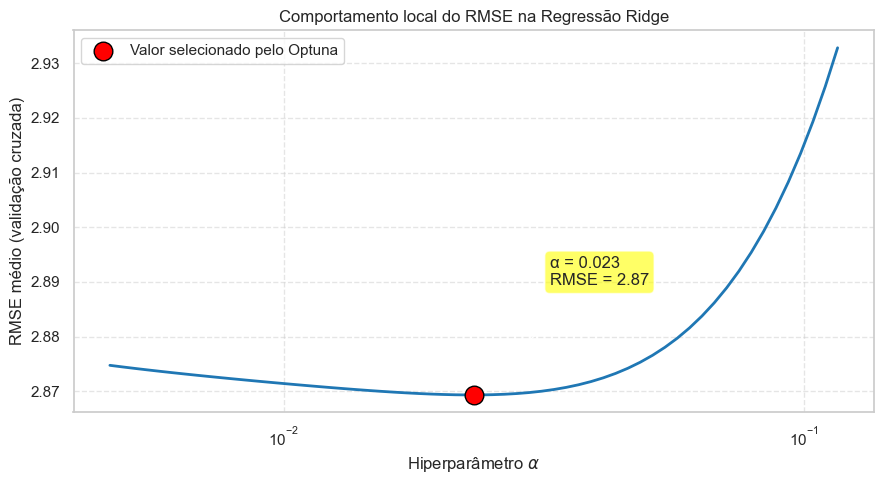

In [42]:
melhor_alpha = estudo_rl2.best_params["alpha"]
melhor_rmse = estudo_rl2.best_value

alphas = np.logspace(
    np.log10(melhor_alpha / 5),
    np.log10(melhor_alpha * 5),
    60
)

rmses = []

for alpha in alphas:

    pipeline = Pipeline([
        ("prep", preprocessador),
        ("ridge", Ridge(alpha=alpha))
    ])

    scores = cross_val_score(
        pipeline,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    rmses.append(-scores.mean())

plt.figure(figsize=(9, 5))

plt.plot(
    alphas,
    rmses,
    color="#1f77b4",
    linewidth=2
)

plt.scatter(
    melhor_alpha,
    melhor_rmse,
    color="red",
    edgecolor="black",
    s=180,
    zorder=5,
    label="Valor selecionado pelo Optuna"
)

plt.annotate(
    f"α = {melhor_alpha:.3f}\nRMSE = {melhor_rmse:.2f}",
    xy=(melhor_alpha, melhor_rmse),
    xytext=(melhor_alpha * 1.4, melhor_rmse + 0.02),
    arrowprops=dict(arrowstyle="->"),
    bbox=dict(
        boxstyle="round,pad=0.3",
        fc="yellow",
        alpha=0.6
    )
)

plt.xscale("log")

plt.xlabel(r"Hiperparâmetro $\alpha$")
plt.ylabel("RMSE médio (validação cruzada)")
plt.title("Comportamento local do RMSE na Regressão Ridge")

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

Observa-se a existência de uma faixa relativamente ampla de valores capazes de produzir desempenhos semelhantes, indicando que a Regressão Ridge apresenta baixa sensibilidade a pequenas variações na intensidade da regularização.

Além disso, nota-se que o valor selecionado pelo `Optuna` ($\alpha \approx 0.023$) encontra-se justamente na região de menor erro observada. Esse resultado sugere que a configuração escolhida fornece um equilíbrio adequado entre ajuste aos dados e regularização dos coeficientes do modelo.

Em contraste com a Regressão Linear tradicional, a introdução da regularização $L_2$ reduziu o $\text{RMSE}$ de $3.60$ para $2.87$ pontos. Entretanto, a Regressão Lasso ainda apresentou desempenho ligeiramente superior, alcançando $\text{RMSE}$ médio de $2.79$ pontos.

<h3>8.3 - Conclusão</h3>

Os resultados obtidos nesta seção evidenciam que modelos lineares são altamente adequados para o problema analisado. A Regressão Linear tradicional já foi capaz de produzir previsões bastante precisas, alcançando $\text{RMSE}$ de $3.60$ pontos.

A introdução de regularização permitiu reduzir ainda mais o erro de previsão. Tanto a Regressão Lasso quanto a Regressão Ridge apresentaram desempenho superior ao modelo linear tradicional, demonstrando que a penalização dos coeficientes contribui para melhorar a capacidade de generalização dos modelos.

Entre as abordagens avaliadas, a Regressão Lasso apresentou o melhor desempenho, com $\text{RMSE}$ médio de $2.79$ pontos, enquanto a Regressão Ridge obteve $\text{RMSE}$ médio de $2.87$ pontos. Esses resultados sugerem que a seleção automática de atributos promovida pela regularização $L_1$ fornece uma pequena vantagem para este conjunto de dados.

Dessa forma, os modelos lineares regularizados passam a representar os melhores resultados obtidos até o momento neste trabalho. Na próxima seção, será investigado um modelo baseado em Árvores de Decisão, capaz de capturar relações não lineares entre os atributos das escolas e a variável alvo.

<h2>9 - Árvore de Decisão</h2>

<h3>9.1 - Modelo inicial</h3>

O próximo modelo avaliado será a Árvore de Decisão. Diferentemente dos modelos lineares analisados anteriormente, as árvores de decisão são capazes de representar relações não lineares entre os atributos e o *target*.

Uma árvore de decisão pode ser interpretada como uma estrutura hierárquica composta por nós e ramificações. O primeiro nó da árvore é denominado nó raiz e contém a primeira regra utilizada para dividir os dados. A partir dele, cada observação percorre diferentes caminhos conforme o resultado das condições avaliadas.

Os nós internos da árvore, chamados de nós de decisão, contêm expressões condicionais aplicadas aos atributos do conjunto de dados. Em cada nó, o algoritmo verifica se uma determinada condição é satisfeita e direciona a observação para um dos ramos subsequentes.

Ao final desse processo, chega-se a um nó folha. Em problemas de regressão, como o presente estudo, cada folha armazena um valor numérico correspondente à previsão realizada pelo modelo. Dessa forma, escolas que percorrem caminhos semelhantes na árvore tendem a receber previsões semelhantes.

Durante o treinamento, o algoritmo procura construir divisões que agrupem observações com valores de resposta parecidos, reduzindo progressivamente a variabilidade existente em cada grupo. Como resultado, a árvore é capaz de capturar interações complexas entre os atributos sem exigir a hipótese de linearidade assumida pelos modelos estudados anteriormente.

Agora então será construída uma versão inicial do modelo para avaliar sua capacidade preditiva antes da etapa de otimização de hiperparâmetros.

Diferentemente do $k$-NN e dos modelos lineares regularizados, as Árvores de Decisão não dependem de medidas de distância nem da magnitude dos atributos para realizar suas decisões. Por esse motivo, não é necessário aplicar etapas de normalização dos dados antes do treinamento do modelo.

In [43]:
from sklearn.tree import DecisionTreeRegressor

pipeline_ad = Pipeline([
    ("arvore", DecisionTreeRegressor(random_state=42))
])

pipeline_ad.fit(X_treino, y_treino.values.ravel())

y_pred_ad = pipeline_ad.predict(X_teste)

RMSE_ad = root_mean_squared_error(
    y_teste,
    y_pred_ad
)

print(f"RMSE: {RMSE_ad:.2f} pontos")

RMSE: 1.44 pontos


O resultado acima nos indica o melhor valor de $\text{RMSE}$ obtido até o momento ($1.44$ pontos). De forma a verificar esse excelente desempenho, vamos realizar validação cruzada com cinco partições.

In [44]:
scores_ad = cross_val_score(
    pipeline_ad,
    X_treino,
    y_treino.values.ravel(),
    cv=5,
    scoring="neg_root_mean_squared_error"
)

rmse_cv_ad = -scores_ad.mean()

print(f"RMSE: {rmse_cv_ad:.2f} pontos")

RMSE: 1.45 pontos


Nessa verificação, observamos um valor muito próximo ao observado anteriormente, sugerindo que o desempenho do modelo não está associado a uma divisão específica dos dados e fornecendo evidências adicionais de que o modelo é capaz de generalizar adequadamente para observações não vistas durante o treinamento.

Vamos então analisar o gráfico $y_{real}$ por $y_{previsto}$:

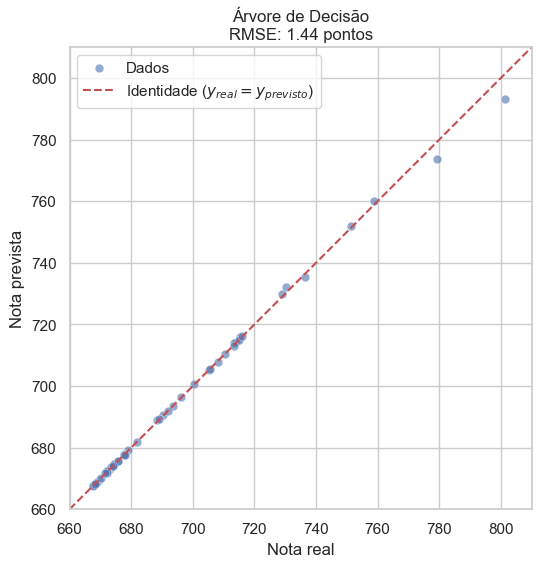

In [45]:
import seaborn as sns
import numpy as np

y_teste_1d = np.array(y_teste).flatten()
y_pred_ad_1d = np.array(y_pred_ad).flatten()

sns.set_theme(
    style="whitegrid",
    rc={"figure.figsize": (6, 6)}
)

intervalo = [660, 810]

eixo = sns.scatterplot(
    x=y_teste_1d,
    y=y_pred_ad_1d,
    alpha=0.6,
    s=40,
    label="Dados"
)

eixo.plot(
    intervalo,
    intervalo,
    "r--",
    linewidth=1.5,
    label="Identidade ($y_{real}=y_{previsto}$)"
)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=f"Árvore de Decisão\nRMSE: {RMSE_ad:.2f} pontos",
    xlim=intervalo,
    ylim=intervalo
)

eixo.set_aspect("equal")

eixo.legend();

É possível verificar que praticamente todos os pontos encontram-se sobre a linha de identidade ($y_{real}=y_{previsto}$), indicando elevada concordância entre os valores observados e as previsões realizadas pelo modelo.

Diferentemente dos modelos lineares avaliados anteriormente, a Árvore de Decisão foi capaz de capturar relações não lineares presentes nos dados, produzindo previsões extremamente próximas dos valores reais. 

Os resultados sugerem que as características das escolas influenciam o *target* por meio de relações mais complexas do que aquelas representadas pelos modelos lineares, favorecendo abordagens baseadas em particionamento recursivo dos dados.

Embora essa configuração da Árvore de Decisão já apresente resultados expressivos, diversos hiperparâmetros podem influenciar diretamente sua complexidade e desempenho. Dessa forma, a seguir vamos realizar uma otimização de hiperparâmetros visando reduzir o $\text{RMSE}$.

<h3>9.2 - Otimização de hiperparâmetros em Árvore de Decisão</h3>

Entre os mais importantes hiperparâmetros desse modelo, estão a profundidade máxima da árvore, o número mínimo de exemplos necessários para realizar divisões e o número mínimo de exemplos presentes em cada folha. Dessa forma, será utilizado o `Optuna` para identificar automaticamente as combinações de hiperparâmetros capazes de minimizar o $\text{RMSE}$ médio obtido anteriormente.

In [64]:
from sklearn.tree import DecisionTreeRegressor

def cria_instancia_modelo_ad(trial):

    parametros = {
        "max_depth": trial.suggest_int(
            "max_depth",
            2,
            30
        ),

        "min_samples_split": trial.suggest_int(
            "min_samples_split",
            2,
            30
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            20
        ),

        "max_features": trial.suggest_categorical(
            "max_features",
            [None, "sqrt", "log2"]
        ),

        "random_state": 42
    }

    return Pipeline([
        ("arvore", DecisionTreeRegressor(**parametros))
    ])

In [65]:
from sklearn.model_selection import cross_val_score

def funcao_objetivo_ad(trial):

    modelo = cria_instancia_modelo_ad(trial)

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [66]:
estudo_ad = optuna.create_study(
    direction="minimize"
)

estudo_ad.optimize(
    funcao_objetivo_ad,
    n_trials=150
)

print("Melhores hiperparâmetros:")
print(estudo_ad.best_params)

print(
    f"\nMelhor RMSE médio: "
    f"{estudo_ad.best_value:.2f} pontos"
)

Melhores hiperparâmetros:
{'max_depth': 17, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None}

Melhor RMSE médio: 1.30 pontos


O processo de otimização identificou uma configuração composta por profundidade máxima igual a $17$ níveis, mínimo de $5$ exemplos para a realização de divisões, mínimo de $1$ exemplo por folha e utilização de todos os atributos disponíveis em cada divisão.

Com essa configuração, o modelo atingiu um $\text{RMSE}$ médio de $1.30$ pontos durante a validação cruzada, representando uma redução de aproximadamente $9.7\%$ em relação à Árvore de Decisão em sua configuração inicial.

Esse resultado sugere que a limitação moderada da profundidade e das condições de divisão contribuiu para melhorar a capacidade de generalização do modelo, reduzindo o erro de previsão sem comprometer sua habilidade de capturar relações não lineares presentes nos dados.

Embora a configuração ótima tenha sido identificada pelo processo de otimização, é interessante compreender quais hiperparâmetros exerceram maior influência sobre o desempenho da árvore. Para isso, o gráfico a seguir apresenta a importância relativa de cada hiperparâmetro durante as combinações avaliadas pelo `Optuna`.

In [67]:
import optuna.visualization as vis 

vis.plot_param_importances(estudo_ad)

No gráfico interativo acima, observa-se que o hiperparâmetro `max_features` exerceu influência dominante sobre o desempenho da Árvore de Decisão, respondendo por aproximadamente $88\%$ da variabilidade observada entre as combinações avaliadas.

Esse resultado indica que a quantidade de atributos disponibilizados para cada divisão da árvore possui impacto muito superior aos demais hiperparâmetros considerados. Em particular, a melhor configuração encontrada utilizou `max_features` = None, permitindo que todos os atributos disponíveis fossem analisados em cada etapa de particionamento dos dados.

Os hiperparâmetros `min_samples_leaf` e `max_depth` apresentaram influência secundária, enquanto `min_samples_split` teve impacto praticamente desprezível no desempenho final do modelo. Dessa forma, os resultados sugerem que a principal fonte de ganho obtida durante a otimização esteve relacionada à estratégia de seleção dos atributos utilizados nas divisões da árvore.

<h3>9.3 - Conclusão</h3>

Os resultados obtidos nesta seção evidenciam o excelente desempenho da Árvore de Decisão para o problema estudado. Mesmo utilizando sua configuração padrão, o modelo apresentou RMSE de $1.44$ pontos, superando todos os algoritmos avaliados anteriormente.

A otimização dos hiperparâmetros permitiu reduzir ainda mais o erro de previsão, alcançando $\text{RMSE}$ médio de $1.30$ pontos durante a validação cruzada. Entre os hiperparâmetros avaliados, observou-se que `max_features` exerceu a maior influência sobre o desempenho do modelo, indicando que a disponibilidade dos atributos durante as divisões da árvore desempenha papel central na qualidade das previsões.

Comparativamente aos modelos lineares e ao $k$-NN, a Árvore de Decisão mostrou-se  adequada para capturar relações não lineares presentes nos dados, produzindo previsões significativamente mais precisas. Até o momento, esse é o melhor desempenho obtido neste trabalho.

Na próxima seção será avaliada a Floresta Aleatória (Random Forest), técnica baseada na combinação de múltiplas Árvores de Decisão, com o objetivo de investigar se a utilização de conjuntos de árvores é capaz de produzir previsões ainda mais precisas.

<h2>10 - Floresta Aleatória</h2>

<h3>10.1 - Modelo inicial</h3>

Embora as Árvores de Decisão apresentem grande capacidade de representar relações não lineares entre os atributos e o *target*, essas estruturas costumam ser sensíveis às particularidades do conjunto de treinamento. Como consequência, pequenas alterações nos dados podem gerar árvores bastante diferentes, aumentando a variância do modelo e favorecendo o sobreajuste.

Uma estratégia para reduzir esse problema consiste em combinar diversas Árvores de Decisão em um único modelo. Essa abordagem pertence à família dos métodos de ensemble, nos quais múltiplos modelos são treinados separadamente e suas previsões são posteriormente agregadas para produzir uma resposta final.

Na Floresta Aleatória (Random Forest), cada árvore é construída a partir de uma amostra aleatória dos dados de treinamento e de subconjuntos aleatórios dos atributos disponíveis. Dessa forma, as árvores produzidas apresentam estruturas diferentes e tendem a cometer erros distintos.

Em problemas de regressão, como o presente estudo, a previsão final é obtida pela média das previsões realizadas por todas as árvores da floresta. Como os erros individuais tendem a se compensar, espera-se que o modelo resultante apresente menor variância e maior capacidade de generalização do que uma única Árvore de Decisão.

Em termos intuitivos, enquanto a Árvore de Decisão pode ser interpretada como a opinião de um único especialista, a Floresta Aleatória corresponde a um comitê formado por diversos especialistas independentes. A decisão final é obtida pela combinação dessas opiniões, produzindo previsões mais estáveis e robustas.

Vamos então construir uma versão inicial da Floresta Aleatória:

In [58]:
from sklearn.ensemble import RandomForestRegressor

pipeline_fa = Pipeline([
    ("fa", RandomForestRegressor(
        random_state=42
    ))
])

pipeline_fa.fit(
    X_treino,
    y_treino.values.ravel()
)

y_pred_fa = pipeline_fa.predict(X_teste)

RMSE_fa = root_mean_squared_error(
    y_teste,
    y_pred_fa
)

print(f"RMSE: {RMSE_fa:.2f} pontos")

RMSE: 2.59 pontos


Embora a Floresta Aleatória seja frequentemente capaz de superar Árvores de Decisão individuais, a configuração padrão utilizada neste primeiro experimento apresentou $\text{RMSE}$ de $2.59$ pontos, valor superior ao obtido pela Árvore de Decisão otimizada. Graficamente, na relação $y_{real}$-$y_{previsto}$, temos:

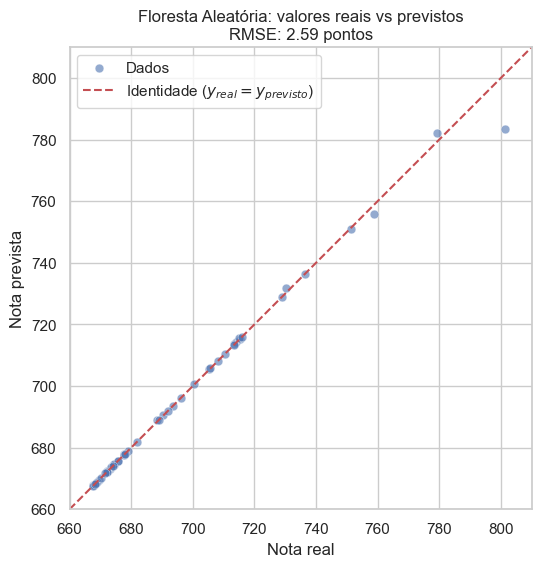

In [59]:
y_teste_1d = np.array(y_teste).flatten()
y_pred_fa_1d = np.array(y_pred_fa).flatten()

sns.set_theme(style="whitegrid", rc={"figure.figsize": (6, 6)})
intervalo = [660, 810]

eixo = sns.scatterplot(x=y_teste_1d, y=y_pred_fa_1d, label="Dados", alpha=0.6, s=40)
eixo.plot(intervalo, intervalo, "r--", label="Identidade ($y_{real} = y_{previsto}$)", linewidth=1.5)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=f"Floresta Aleatória: valores reais vs previstos\nRMSE: {RMSE_fa:.2f} pontos",
    xlim=intervalo,
    ylim=intervalo,
    aspect="equal",
)

eixo.legend();

Aqui pode-se observar que a maior parte dos pontos permanece próxima à linha de identidade ($y_{real}=y_{previsto}$), indicando boa concordância entre as previsões realizadas pelo modelo e os valores observados.

Embora o desempenho obtido seja superior ao dos modelos lineares avaliados anteriormente, nota-se uma dispersão ligeiramente maior em relação à observada para a Árvore de Decisão otimizada. Esse comportamento é refletido pelo $\text{RMSE}$ de $2.59$ pontos, sugerindo que a configuração padrão da floresta ainda não explora plenamente o potencial do algoritmo.

Os maiores desvios concentram-se em escolas com notas mais elevadas, para as quais o modelo tende a produzir previsões ligeiramente inferiores aos valores observados. Ainda assim, os resultados confirmam que a combinação de múltiplas árvores é capaz de produzir previsões bastante precisas para o problema estudado.

Entretanto, o desempenho inferior ao da Árvore de Decisão otimizada indica que a configuração inicial da Floresta Aleatória não é necessariamente a mais adequada para este conjunto de dados. Como esse algoritmo possui diversos hiperparâmetros capazes de influenciar o número de árvores geradas, sua profundidade, as condições de divisão dos nós e o subconjunto de atributos utilizado em cada árvore, torna-se necessário investigar configurações alternativas.

Dessa forma, vamos realizar uma etapa de otimização de hiperparâmetros, com o objetivo de identificar combinações capazes de reduzir o erro de previsão e explorar de maneira mais eficiente o potencial da Floresta Aleatória.

<h3>10.2 - Otimização de hiperparâmetros em Floresta Aleatória</h3>

A Floresta Aleatória possui um número significativamente maior de hiperparâmetros do que os modelos avaliados anteriormente. Além disso, cada combinação avaliada durante a otimização exige o treinamento simultâneo de múltiplas Árvores de Decisão, associado à validação cruzada utilizada para estimar o desempenho do modelo.

Como consequência, o custo computacional da busca cresce substancialmente. Dessa forma, antes de realizar uma busca extensa no espaço de hiperparâmetros, vamos conduzir uma etapa exploratória utilizando apenas $10$ combinações geradas pelo `Optuna`. O objetivo dessa análise preliminar é compreender o comportamento do modelo, validar o espaço de busca definido e estimar o esforço computacional necessário para uma otimização mais abrangente.

In [68]:
from sklearn.ensemble import RandomForestRegressor

def cria_instancia_modelo_fa(trial):

    parametros = {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            50,
            500
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            2,
            30
        ),

        "min_samples_split": trial.suggest_int(
            "min_samples_split",
            2,
            30
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            20
        ),

        "max_features": trial.suggest_categorical(
            "max_features",
            [None, "sqrt", "log2"]
        ),

        "bootstrap": trial.suggest_categorical(
            "bootstrap",
            [True, False]
        ),

        "random_state": 42
    }

    return Pipeline([
        ("fa", RandomForestRegressor(**parametros))
    ])

In [69]:
from sklearn.model_selection import cross_val_score

def funcao_objetivo_fa(trial):

    modelo = cria_instancia_modelo_fa(trial)

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [70]:
estudo_fa = optuna.create_study(
    direction="minimize"
)

estudo_fa.optimize(
    funcao_objetivo_fa,
    n_trials=10
)

print("Melhores hiperparâmetros:")
print(estudo_fa.best_params)

print(
    f"\nMelhor RMSE médio: "
    f"{estudo_fa.best_value:.2f} pontos"
)

Melhores hiperparâmetros:
{'n_estimators': 150, 'max_depth': 14, 'min_samples_split': 12, 'min_samples_leaf': 1, 'max_features': None, 'bootstrap': False}

Melhor RMSE médio: 2.01 pontos


Mesmo com uma busca exploratória limitada a apenas $10$ combinações, o processo de otimização foi capaz de reduzir o RMSE médio de $2.59$ para $2.01$ pontos, correspondendo a uma redução aproximada de $22.4\%$ no erro de previsão.

Os resultados obtidos indicam que o desempenho da Floresta Aleatória é altamente sensível à escolha de seus hiperparâmetros. Em particular, observou-se uma preferência por florestas compostas por um número relativamente elevado de árvores e por restrições adicionais ao processo de divisão dos nós, sugerindo que mecanismos de controle da complexidade contribuem para melhorar a capacidade de generalização do modelo.

Apesar da melhora observada, a busca realizada até este ponto avaliou apenas uma pequena fração do espaço de hiperparâmetros disponível. Considerando o elevado custo computacional da Floresta Aleatória, torna-se inviável executar localmente buscas muito extensas em tempo razoável. Dessa forma, serão utilizados recursos de Computação de Alto Desempenho ($HPC$), permitindo avaliar um número significativamente maior de combinações de hiperparâmetros e realizar uma exploração mais abrangente do espaço de busca do modelo.

<h4>10.2.1 - Otimização usando $HPC$</h4>

A busca ampliada realizada no cluster Heisenberg avaliou $150$ combinações distintas de hiperparâmetros. Para isso, foi desenvolvido um script Python responsável pela execução da otimização e um arquivo de submissão (*job script*) para gerenciamento do processo pelo sistema de filas do cluster. Os arquivos random_forest_optuna.py e job_rf.sh, responsáveis pela execução da otimização no cluster Heisenberg, encontram-se disponíveis no repositório do projeto.

A otimização realizada no $HPC$ identificou a seguinte configuração como a mais eficiente:

- `n_estimators` $= 477$
- `max_depth` $= 24$
- `min_samples_split` $= 2$
- `min_samples_leaf` $= 1$
- `max_features` $=$ None
- `bootstrap` $=$ True

Utilizando essa configuração, a Floresta Aleatória atingiu $\text{RMSE}$ médio de $1.17$ pontos durante a validação cruzada. Comparando os resultados obtidos, observa-se que a busca ampliada realizada no $HPC$ reduziu o $\text{RMSE}$ de $2.01$ para $1.17$ pontos em relação à busca exploratória local. Em comparação com a configuração inicial do modelo ($\text{RMSE} = 2.59$ pontos), a redução total do erro foi superior a $50\%$.

Além da melhora preditiva, a execução no cluster permitiu avaliar uma quantidade significativamente maior de combinações de hiperparâmetros em aproximadamente $236$ segundos de processamento, tornando viável uma exploração mais abrangente do espaço de busca da Floresta Aleatória.

É interessante também analisar como o processo de otimização evoluiu ao longo dos $150$ trials executados no $HPC$. O gráfico a seguir apresenta o $\text{RMSE}$ médio obtido em cada combinação de hiperparâmetros avaliada pelo `Optuna`.

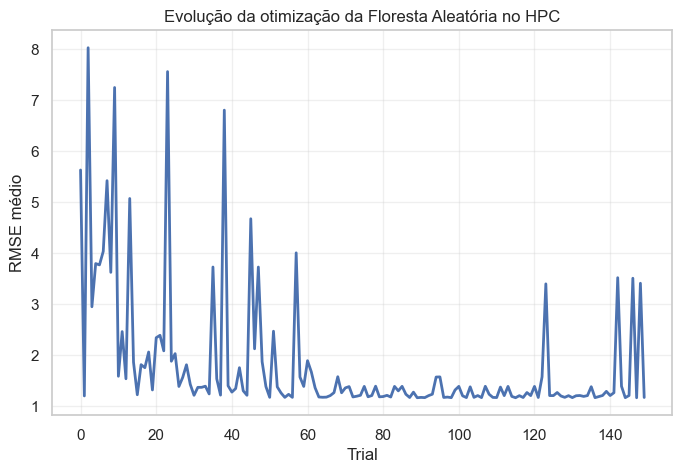

In [81]:
trials_rf = pd.read_csv(
    "trials_random_forest.csv"
)

plt.figure(figsize=(8,5))

plt.plot(
    trials_rf["number"],
    trials_rf["value"],
    linewidth=2
)

plt.xlabel("Trial")
plt.ylabel("RMSE médio")
plt.title(
    "Evolução da otimização da Floresta Aleatória no HPC"
)

plt.grid(alpha=0.3)

plt.show()

O gráfico evidencia que os primeiros trials apresentaram elevada variabilidade de desempenho, com $\text{RMSE}$s variando entre aproximadamente $1$ e $8$ pontos. Esse comportamento é esperado, uma vez que o Optuna ainda estava explorando diferentes regiões do espaço de hiperparâmetros e avaliando configurações com qualidades bastante distintas.

À medida que novos trials foram executados, percebe-se uma concentração crescente dos resultados próximos aos menores valores de $\text{RMSE}$. Em outras palavras, o processo de otimização passou a explorar regiões progressivamente mais promissoras do espaço de busca, reduzindo a frequência de configurações com desempenho insatisfatório.

Também é possível observar a presença de alguns picos isolados ao longo da execução, inclusive em trials mais avançados. Esses picos indicam que o algoritmo continuou explorando alternativas diferentes durante todo o processo de otimização, evitando concentrar-se prematuramente em uma única região do espaço de busca.

De forma geral, o gráfico evidencia a eficiência do processo de otimização, que foi capaz de identificar configurações cada vez melhores ao longo dos trials, culminando na obtenção do $\text{RMSE}$ médio de $1.17$ pontos, o menor valor observado para a Floresta Aleatória neste trabalho.

Agora, assim como analisamos o impacto de cada hiperparâmetro na capacidade preditiva do modelo para a Árvore de Decisão, vamos executar esse processo para a Floresta Aleatória otimizada:

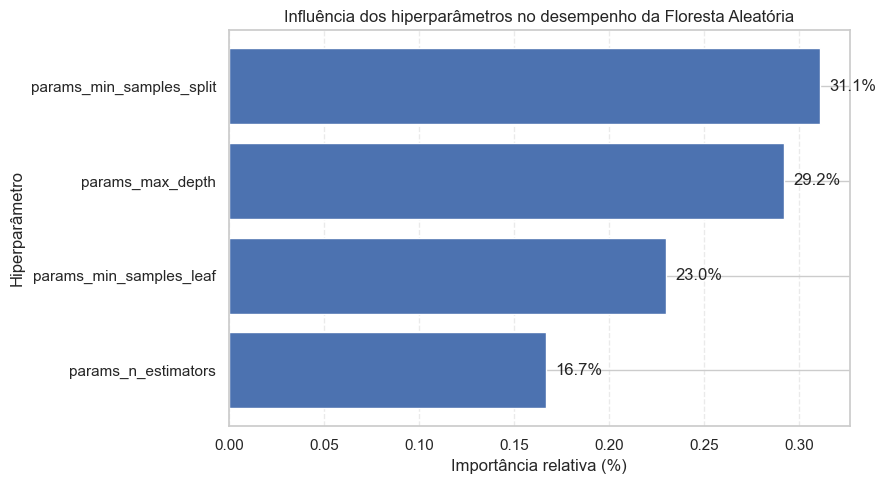

In [104]:
X_imp = trials_rf[
    [
        "params_n_estimators",
        "params_max_depth",
        "params_min_samples_split",
        "params_min_samples_leaf"
    ]
]

y_imp = trials_rf["value"]

modelo_imp = RandomForestRegressor(
    random_state=42
)

modelo_imp.fit(
    X_imp,
    y_imp
)

importancias = modelo_imp.feature_importances_

ordem = np.argsort(importancias)

plt.figure(figsize=(9, 5))

barras = plt.barh(
    np.array(X_imp.columns)[ordem],
    np.array(importancias)[ordem],
    color="#4c72b0"
)

for barra in barras:

    valor = barra.get_width()

    plt.text(
        valor + 0.005,
        barra.get_y() + barra.get_height()/2,
        f"{valor*100:.1f}%",
        va="center"
    )

plt.xlabel("Importância relativa (%)")
plt.ylabel("Hiperparâmetro")

plt.title(
    "Influência dos hiperparâmetros no desempenho da Floresta Aleatória"
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

Nesse gráfico, observa-se que os hiperparâmetros associados à estrutura das árvores individuais exerceram a maior influência sobre o desempenho final do modelo. O hiperparâmetro `min_samples_split` respondeu por aproximadamente $31.1\%$ da variabilidade observada nos resultados, seguido por `max_depth` ($29.2\%$) e `min_samples_leaf` ($23.0\%$). Esses resultados indicam que a forma como a floresta controla o crescimento e o particionamento das árvores é mais importante para o desempenho preditivo do que o simples aumento do número de árvores.

Por outro lado, o hiperparâmetro `n_estimators`, embora relevante, apresentou a menor importância relativa entre os parâmetros analisados ($16,7\%$). Isso sugere que o ganho de desempenho obtido pela Floresta Aleatória não decorreu apenas da utilização de um grande número de árvores, mas principalmente do ajuste adequado da complexidade das árvores que compõem a floresta.

Em conjunto, esses resultados ajudam a explicar a redução do $\text{RMSE}$ de $2.59$ para $1.17$ pontos observada após a otimização. A busca realizada no HPC foi capaz de identificar uma combinação de hiperparâmetros que produziu árvores suficientemente complexas para capturar os padrões presentes nos dados, mas sem comprometer a capacidade de generalização do modelo.

<h3>10.3 - Conclusão</h3>

Os resultados obtidos nesta seção demonstram o potencial da Floresta Aleatória para a tarefa de previsão das notas das escolas. Embora a configuração padrão do algoritmo já tenha apresentado desempenho superior aos modelos lineares avaliados anteriormente, a otimização dos hiperparâmetros mostrou-se fundamental para explorar adequadamente o potencial do modelo.

A busca exploratória realizada localmente permitiu reduzir o $\text{RMSE}$ de $2.59$ para $2.01$ pontos, evidenciando a importância da escolha adequada dos hiperparâmetros. Posteriormente, uma busca ampliada executada na infraestrutura $HPC$ permitiu avaliar $150$ combinações distintas de hiperparâmetros, resultando em um $\text{RMSE}$ médio de $1.17$ pontos.

A análise dos hiperparâmetros indicou que os hiperparâmetros relacionados à estrutura das árvores individuais exerceram maior influência sobre o desempenho do modelo do que o simples aumento da quantidade de árvores da floresta. Esse resultado sugere que o controle adequado da complexidade das árvores desempenha papel fundamental na capacidade preditiva do algoritmo.

Com $\text{RMSE}$ médio de $1.17$ pontos, a Floresta Aleatória apresentou o melhor desempenho observado até o momento neste trabalho, superando inclusive a Árvore de Decisão otimizada. Esses resultados evidenciam a capacidade dos métodos de ensemble em produzir previsões mais robustas e precisas por meio da combinação de múltiplos modelos.

Na próxima seção será avaliado o algoritmo Gradient Boosting, outra técnica baseada em conjuntos de árvores, porém construída de forma sequencial, permitindo investigar se essa estratégia é capaz de produzir ganhos adicionais de desempenho.

<h2>11 - Gradient Boosting</h2>

<h3>11.1 - Modelo inicial</h3>

O próximo modelo avaliado será o Gradient Boosting. Assim como a Floresta Aleatória, esse algoritmo pertence à família dos métodos de ensemble baseados em Árvores de Decisão. Entretanto, a forma como as árvores são construídas é significativamente diferente.

Enquanto a Floresta Aleatória treina diversas árvores de maneira independente e combina suas previsões por meio de uma média, o Gradient Boosting constrói as árvores de forma sequencial. Nesse processo, cada nova árvore é treinada com o objetivo de corrigir os erros cometidos pelo conjunto de árvores construído até aquele momento.

Como consequência, o modelo passa a aprender progressivamente padrões que ainda não foram adequadamente representados pelas árvores anteriores. Em problemas de regressão, a previsão final é obtida pela soma das contribuições de todas as árvores que compõem o ensemble.

Essa estratégia permite capturar relações complexas presentes nos dados e frequentemente produz modelos de elevada precisão preditiva. Por outro lado, a construção sequencial aumenta a sensibilidade aos hiperparâmetros do modelo e eleva significativamente o custo computacional da etapa de treinamento.

Vamos montar um modelo inicial:

In [83]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    random_state=42
)

gb.fit(
    X_treino,
    y_treino.values.ravel()
)

y_pred_gb = gb.predict(X_teste)

RMSE_gb = root_mean_squared_error(
    y_teste,
    y_pred_gb
)

print(
    f"RMSE: {RMSE_gb:.2f} pontos"
)

RMSE: 1.74 pontos


Aqui verificamos um $\text{RMSE}$ de $1.74$ pontos, já superando todos os modelos lineares e a Floresta Aleatória padrão, mas ainda ficando atrás da Árvore de Decisão otimizada ($1.30$ pontos) e da Random Forest otimizada ($1.17$ pontos). Analisemos o gráfico $y_{real}$-$y_{previsto}$:

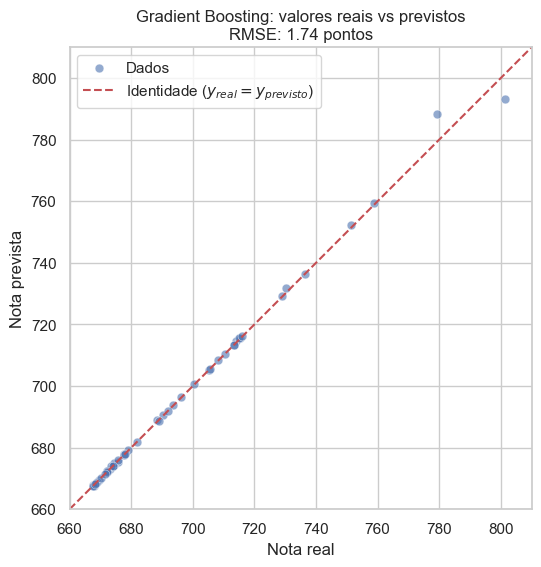

In [84]:
y_teste_1d = np.array(y_teste).flatten()
y_pred_gb_1d = np.array(y_pred_gb).flatten()

sns.set_theme(style="whitegrid", rc={"figure.figsize": (6, 6)})
intervalo = [660, 810]

eixo = sns.scatterplot(x=y_teste_1d, y=y_pred_gb_1d, label="Dados", alpha=0.6, s=40)
eixo.plot(intervalo, intervalo, "r--", label="Identidade ($y_{real} = y_{previsto}$)", linewidth=1.5)

eixo.set(
    xlabel="Nota real",
    ylabel="Nota prevista",
    title=f"Gradient Boosting: valores reais vs previstos\nRMSE: {RMSE_gb:.2f} pontos",
    xlim=intervalo,
    ylim=intervalo,
    aspect="equal",
)

eixo.legend();

O gráfico evidencia que o modelo foi capaz de reproduzir adequadamente a tendência geral presente nos dados, com a maior parte das previsões acompanhando a evolução das notas observadas. Entretanto, ainda é possível identificar alguns desvios mais perceptíveis nas extremidades da distribuição, indicando que determinados padrões não foram completamente capturados pela configuração padrão do algoritmo.

Além disso, observa-se que os erros apresentam comportamento relativamente sistemático em algumas regiões do gráfico, sugerindo que ajustes na complexidade do modelo e no processo de aprendizado podem contribuir para melhorar a qualidade das previsões.

Essas observações são consistentes com o $\text{RMSE}$ obtido anteriormente e indicam que ainda existe espaço para aprimorar o desempenho do Gradient Boosting por meio da escolha adequada de seus hiperparâmetros. Dessa forma, na próxima subseção será realizada uma etapa de otimização, buscando identificar combinações capazes de reduzir ainda mais o erro de previsão do modelo.

<h3>11.2 - Otimização de hiperparâmetros no Gradient Boosting</h3>

Assim como observado na Floresta Aleatória, o desempenho do Gradient Boosting depende fortemente da escolha de seus hiperparâmetros. Como as árvores são construídas sequencialmente, hiperparâmetros relacionados à taxa de aprendizado, ao número de árvores utilizadas e à complexidade de cada árvore podem influenciar significativamente a capacidade de generalização do modelo.

Entretanto, assim como observado na Floresta Aleatória, a avaliação de um grande número de combinações pode demandar tempo computacional significativo. Dessa forma, antes de realizar uma busca ampliada utilizando recursos de Computação de Alto Desempenho ($HPC$), será conduzida uma etapa exploratória com apenas $10$ combinações de hiperparâmetros geradas pelo `Optuna`. O objetivo dessa análise preliminar é verificar a sensibilidade do modelo aos hiperparâmetros considerados e estimar seu potencial de melhoria em relação à configuração padrão.

In [85]:
from sklearn.ensemble import GradientBoostingRegressor

def cria_instancia_modelo_gb(trial):

    parametros = {

        "n_estimators": trial.suggest_int(
            "n_estimators",
            50,
            500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.3,
            log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            2,
            10
        ),

        "min_samples_split": trial.suggest_int(
            "min_samples_split",
            2,
            30
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            20
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.5,
            1.0
        ),

        "random_state": 42
    }

    return GradientBoostingRegressor(
        **parametros
    )

In [86]:
from sklearn.model_selection import cross_val_score

def funcao_objetivo_gb(trial):

    modelo = cria_instancia_modelo_gb(
        trial
    )

    scores = cross_val_score(
        modelo,
        X_treino,
        y_treino.values.ravel(),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [88]:
estudo_gb = optuna.create_study(
    direction="minimize"
)

estudo_gb.optimize(
    funcao_objetivo_gb,
    n_trials=10
)

print("Melhores hiperparâmetros:")
print(estudo_gb.best_params)

print(
    f"\nMelhor RMSE médio: "
    f"{estudo_gb.best_value:.2f} pontos"
)

Melhores hiperparâmetros:
{'n_estimators': 408, 'learning_rate': 0.07303812511144404, 'max_depth': 4, 'min_samples_split': 17, 'min_samples_leaf': 1, 'subsample': 0.5491213110978009}

Melhor RMSE médio: 1.15 pontos


Mesmo considerando apenas uma busca exploratória limitada a $10$ combinações de hiperparâmetros, o Gradient Boosting apresentou uma redução expressiva do erro de previsão, alcançando $\text{RMSE}$ médio de $1.15$ pontos.

Esse resultado representa uma melhora substancial em relação à configuração padrão do modelo ($\text{RMSE} = 1.74$ pontos) e supera, ainda que por pequena margem, o melhor resultado obtido anteriormente pela Floresta Aleatória otimizada ($RMSE = 1.17$ pontos).

Além disso, a melhora obtida a partir de uma quantidade tão reduzida de combinações sugere que o espaço de busca ainda não foi explorado adequadamente. Dessa forma, torna-se interessante realizar uma busca mais abrangente utilizando recursos de Computação de Alto Desempenho ($HPC$), permitindo avaliar um número significativamente maior de combinações de hiperparâmetros em tempo viável.

<h4>11.2.1 - Otimização usando $HPC$</h4>

Os resultados da busca exploratória de $10$ trials forneceram indícios importantes sobre regiões promissoras do espaço de hiperparâmetros. Em particular, observou-se uma tendência favorável à utilização de um número elevado de árvores, profundidades relativamente moderadas e taxas de aprendizado intermediárias.

Com base nesses resultados preliminares, os intervalos de busca foram ajustados de forma a concentrar a exploração em regiões mais promissoras do espaço de hiperparâmetros. Essa estratégia permite utilizar os recursos computacionais do $HPC$ de maneira mais eficiente, evitando avaliações excessivas em regiões que já demonstraram baixa probabilidade de produzir modelos competitivos.

A busca ampliada realizada no cluster Heisenberg avaliou $150$ combinações distintas de hiperparâmetros utilizando o `Optuna`. A melhor configuração encontrada foi:

- `n_estimators` $= 363$
- `learning_rate` $\approx 0.0376$
- `max_depth` $= 8$
- `min_samples_split` $= 24$
- `min_samples_leaf` $= 1$
- `subsample` $\approx 0.713$

Com essa configuração, o modelo atingiu $\text{RMSE}$ médio de $0.86$ pontos durante a validação cruzada.


Comparando os resultados obtidos, observa-se uma redução significativa do erro em relação à configuração padrão do modelo ($\text{RMSE} = 1.74$ pontos) e também em relação à busca exploratória inicial utilizando apenas $10$ combinações de hiperparâmetros ($\text{RMSE} = 1.15$ pontos).

Esse comportamento evidencia a importância da otimização dos hiperparâmetros para o Gradient Boosting e demonstra que uma exploração mais abrangente do espaço de busca foi capaz de identificar configurações superiores.

Analisemos a evolução do $\text{RMSE}$ ao longo dos $150$ trials executados no $HPC$.

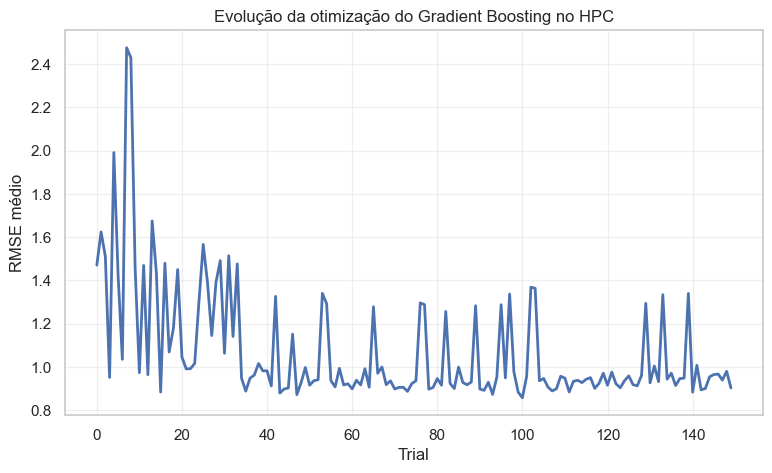

In [93]:
trials_gb = pd.read_csv(
    "trials_gradient_boosting.csv"
)

plt.figure(figsize=(9,5))

plt.plot(
    trials_gb["number"],
    trials_gb["value"],
    linewidth=2
)

plt.xlabel("Trial")
plt.ylabel("RMSE médio")
plt.title(
    "Evolução da otimização do Gradient Boosting no HPC"
)

plt.grid(alpha=0.3)

plt.show()

É possível observar que as primeiras combinações avaliadas produziram resultados bastante variados, refletindo a exploração inicial de diferentes regiões do espaço de hiperparâmetros. Com o avanço da otimização, o `Optuna` passou a identificar regiões progressivamente mais promissoras, reduzindo gradualmente os valores de $\text{RMSE}$ até atingir o valor mínimo de $0.86$ pontos.
Esse comportamento evidencia a eficiência do processo de otimização em direcionar a busca para configurações cada vez mais adequadas ao problema estudado.

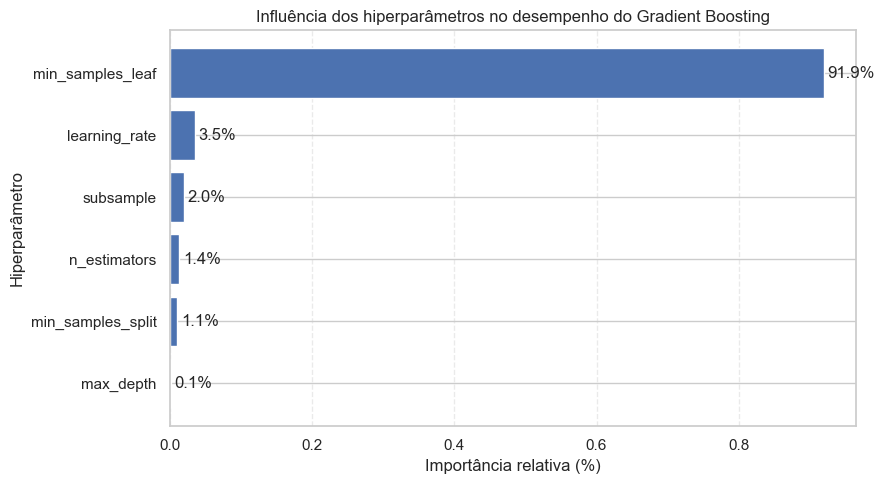

In [103]:
from sklearn.ensemble import GradientBoostingRegressor
import matplotlib.pyplot as plt
import numpy as np

X_imp = trials_gb[
    [
        "params_n_estimators",
        "params_learning_rate",
        "params_max_depth",
        "params_min_samples_split",
        "params_min_samples_leaf",
        "params_subsample"
    ]
]

y_imp = trials_gb["value"]

modelo_imp = GradientBoostingRegressor(
    n_estimators=500,
    random_state=42
)

modelo_imp.fit(
    X_imp,
    y_imp
)

importancias = modelo_imp.feature_importances_

nomes = [
    "n_estimators",
    "learning_rate",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "subsample"
]

ordem = np.argsort(importancias)

plt.figure(figsize=(9, 5))

barras = plt.barh(
    np.array(nomes)[ordem],
    np.array(importancias)[ordem],
    color="#4c72b0"
)

for barra in barras:

    valor = barra.get_width()

    plt.text(
        valor + 0.005,
        barra.get_y() + barra.get_height() / 2,
        f"{valor*100:.1f}%",
        va="center"
    )

plt.xlabel("Importância relativa (%)")
plt.ylabel("Hiperparâmetro")

plt.title(
    "Influência dos hiperparâmetros no desempenho do Gradient Boosting"
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

Verifica-se que o hiperparâmetro `min_samples_leaf` exerceu influência dominante sobre o desempenho do modelo, respondendo por aproximadamente $91.9\%$ da variabilidade observada entre os trials avaliados. Esse resultado indica que a quantidade mínima de exemplos permitida em cada folha teve impacto muito superior aos demais hiperparâmetros considerados.

Em comparação, hiperparâmetros frequentemente associados ao desempenho do Gradient Boosting, como `learning_rate` e `n_estimators`, apresentaram influência relativamente menor na variabilidade observada entre os trials. Isso sugere que, para o conjunto de dados estudado, a capacidade de controlar o nível de detalhamento das divisões realizadas pelas árvores foi mais importante do que o simples aumento da quantidade de estimadores ou alterações na taxa de aprendizado.

Também é interessante notar que os hiperparâmetros `max_depth` e `min_samples_split` apresentaram influência praticamente desprezível sobre o desempenho final do modelo. Isso sinaliza que, dentro da região do espaço de busca explorada pelo Optuna, diferentes valores desses parâmetros produziram modelos com desempenhos bastante semelhantes.

Em conjunto, esses resultados ajudam a explicar a redução do $\text{RMSE}$ de $1.74$ para $0.86$ pontos observada ao longo do processo de otimização, evidenciando a importância do ajuste adequado dos hiperparâmetros para o desempenho do Gradient Boosting.

<h3>11.3 - Conclusão</h3>

Os resultados obtidos nesta seção evidenciam o elevado potencial do Gradient Boosting para a tarefa de previsão das notas das escolas. Mesmo utilizando sua configuração padrão, o modelo apresentou desempenho competitivo, alcançando $\text{RMSE}$ de $1.74$ pontos. Entretanto, a otimização dos hiperparâmetros mostrou-se fundamental para explorar adequadamente o potencial do algoritmo, permitindo reduzir o erro para $0.86$ pontos.

Comparativamente aos demais modelos avaliados, o Gradient Boosting apresentou o menor RMSE observado em todo o trabalho, superando inclusive a Floresta Aleatória otimizada ($1.17$ pontos). Esse resultado sugere que a estratégia de construção sequencial das árvores foi particularmente eficaz para capturar os padrões presentes nos dados.

Dessa forma, o Gradient Boosting passa a representar o modelo de melhor desempenho entre todas as abordagens avaliadas neste estudo, constituindo uma forte candidata à solução final do problema proposto.

<h2>12 - Comparação dos modelos</h2>

Ao longo deste trabalho foram avaliadas diferentes abordagens de Aprendizado de Máquina para a previsão das notas das escolas. Inicialmente, foi utilizado um modelo de referência (baseline), seguido por algoritmos baseados em vizinhança, modelos lineares e métodos baseados em árvores.

Para cada algoritmo, foram analisados o desempenho inicial, o impacto da otimização dos hiperparâmetros e, quando pertinente, a utilização de recursos de Computação de Alto Desempenho ($HPC$) para ampliar a exploração do espaço de busca.

Nesta seção, os resultados obtidos serão comparados de forma consolidada, permitindo identificar quais algoritmos apresentaram melhor capacidade preditiva e quais características contribuíram para seu desempenho.

<h3>12.1 - Comparação do desempenho preditivo</h3>

A forma mais direta de comparar os algoritmos avaliados consiste em analisar o RMSE obtido após as etapas de otimização. Como essa métrica expressa o erro médio de previsão na mesma escala da variável alvo, valores menores indicam modelos mais precisos.

A tabela abaixo apresenta um resumo dos menores valores de $\text{RMSE}$ obtidos para cada algoritmo ao longo deste trabalho, considerando as configurações finais selecionadas após as etapas de otimização.

| Modelo | RMSE |
| :--- | :---: |
| Baseline | 30.64 |
| k-NN | 6.17 |
| Regressão Linear | 3.60 |
| Ridge | 2.87 |
| Lasso | 2.79 |
| Árvore de Decisão | 1.30 |
| Floresta Aleatória | 1.17 |
| Gradient Boosting | 0.86 |

A tabela nos mostra uma redução progressiva do erro à medida que modelos mais sofisticados são introduzidos. Os modelos lineares já apresentaram ganhos significativos em relação ao $k$-NN, porém os maiores avanços ocorreram nos métodos baseados em árvores. Entre todos os algoritmos avaliados, o Gradient Boosting apresentou o menor $\text{RMSE}$, atingindo $0.86$ pontos após a otimização dos hiperparâmetros.

Embora a comparação dos valores de RMSE forneça uma visão geral do desempenho dos modelos, essa análise ainda depende das avaliações realizadas ao longo das seções anteriores. Para realizar uma comparação mais robusta e menos dependente de uma única divisão dos dados, será utilizada validação cruzada com cinco partições. Essa abordagem permite estimar simultaneamente o desempenho médio e a variabilidade de cada algoritmo, fornecendo uma avaliação mais confiável da capacidade de generalização dos modelos.

<h3>12.2 - Comparação por validação cruzada</h3>

<h2>Referências bibliográficas</h2>

[1] Enem. Disponível em: <http://www.gov.br/inep/pt-br/areas-de-atuacao/avaliacao-e-exames-educacionais/enem>. Acesso em: 17 ago. 2026.

[2] CAPUTO, Gabriela. **Enem: como funciona a TRI Por que duas pessoas com acertos iguais tiram notas**, G1. Disponível em: <https://g1.globo.com/educacao/enem/2025/noticia/2025/11/05/enem-como-funciona-a-tri-por-que-duas-pessoas-com-acertos-iguais-tiram-notas-diferentes.ghtml>. Acesso em: 17 ago. 2026.

[3] What are Distance Metrics? | IBM. Disponível em: https://www.ibm.com/think/topics/distance-metrics. Acesso em: 22 ago. 2026.